# A/B transition rates in active droplets

Every chain is A (n_pSer < `THRESHOLD`) or B (n_pSer ≥ `THRESHOLD`) and in/out of the condensate (optionally at the interface).
1. **Build timelines** from the reaction file and the dumps; saved as json (used also by `zwicker_theory.ipynb`)
2. 2-state A/B rates and lifetimes
3. 4-state rates, cycle $\Delta\mu$, fluxes and turnover
4. 6-state (with interface) rates and cycles
5. In/out rates in time
6. Position of the reactions with respect to the condensate

Timeline functions are in `hpa.timelines`.

Saved results (in the analysis folder of each system), so the figures can be re-run without the dumps:
- section 1: timelines (4 and 6 states), transition counts and residences; computed only if missing
- sections 3-4: cycle $\Delta\mu$ with errors, `dmu_4states_*.txt` and `dmu_6states_*.txt`
- section 6: reaction distances `sim{ss}_reaction_distances*.npz` and radial profiles `sim{ss}_radial_profiles*.npz`

Set `RECOMPUTE = True` in the setup cell to redo the saved timelines, distances and profiles.

Definitions: in the 4-state timelines a chain is *in* if more than half of its beads are in the largest cluster of
TDP-43 beads; in the 6-state timelines a chain with any bead in that cluster is *in* or *interface*.

**Choose the run with `RUN` in the setup cell.** `RUN = ''` is the original run (200k-step dumps, outputs keep
their original names, also read by `zwicker_theory.ipynb` and `active_droplets.ipynb`); `RUN = '50k'` is the
continuation with dumps every 50k steps: every output file and figure gets the suffix `_50k`, so the original
analysis is never overwritten.

# Setup

In [1]:
import os
import sys

module_path = os.path.abspath('src')    # run the notebooks from the repository folder
if module_path not in sys.path:
    sys.path.insert(0, module_path)
from hpa.paths import SIM, AN, PL, INPUT_STATS, REPO, STYLES   # data locations (set HPA_DATA_ROOT to use another copy)

import numpy as np
import networkx as nx
from matplotlib import pyplot as plt
from scipy.integrate import quad
from scipy.optimize import curve_fit
from tqdm import tqdm
import gsd.hoomd
import freud

import hpa.msm
import hpa.timelines as hpt
import hpa.profiles
import hpa.trajectory
from hpa.stats import mean_err, tanh_general

plt.style.use('default')
plt.style.use(STYLES + 'rates_plot.mplstyle')

/localscratch/zippoema/lib/python_envs/hpa_env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/localscratch/zippoema/lib/python_envs/hpa_env/lib/python3.11/site-packages/MDAnalysis/topology/TPRParser.py:160: DeprecationWarning: 'xdrlib' is deprecated and slated for removal in Python 3.13
  import xdrlib


In [ ]:
path_drop_fr = SIM + 'droplet_200-tdp43-lcd/'
path_drop_fr_an = AN + 'droplet_200-tdp43-lcd/'
path_drop_fr_pl = PL + 'droplet_200-tdp43-lcd/'

N_CHAINS = 200       # TDP-43 LCD chains
CHAIN_LENGTH = 154
THRESHOLD = 8        # chains with >= THRESHOLD pSer are B, the others A
SIMS = [1, 2, 3]
MD_DT_PS = 0.01      # MD time step in ps (1e8 steps = 1 us)

# ---- which run to analyse --------------------------------------------------
# ''    : original run, dumps every 200k steps: _fr01_dump (0-2e9) + _fr01_20us_dump (2e9-3e9);
#         outputs keep their original names
# '50k' : continuation of the 20 us run (starts from _fr01_20us_end.gsd, step counter reset to 0),
#         dumps every 50k steps, 0-5e8 steps; all outputs get the suffix _50k
# RUN = '50k'
RUN = ''

RUNS = {
    '': dict(
        dt_snap=200000,
        t_therm=10**9,                                   # MD steps discarded before building the timelines
        start='_fr01_start.gsd',                         # initial pSer pattern
        dumps=['_fr01_start.gsd', '_fr01_dump.gsd', '_fr01_20us_dump.gsd'],
        contacts='_fr01_20us_contacts.txt',              # cumulative reaction file
        reaction_dump='_fr01_dump.gsd',                  # section 6: reaction positions
        reaction_contacts='_fr01_contacts.txt',
        centered_dump='_fr01_20us_dump_centered.gsd',    # section 6: density profiles
    ),
    '50k': dict(
        dt_snap=50000,
        t_therm=0,                                       # already at steady state (continues the 20 us run)
        start='_fr01_20us_end.gsd',
        dumps=['_fr01_50k_dump.gsd'],
        contacts='_fr01_50k_contacts.txt',
        reaction_dump='_fr01_50k_dump.gsd',
        reaction_contacts='_fr01_50k_contacts.txt',
        centered_dump='_fr01_50k_dump_centered.gsd',     # not created yet (centre the dump as for the other runs)
    ),
}
RUN_FILES = RUNS[RUN]
TAG = f'_{RUN}' if RUN else ''    # appended to every output file name
DT_SNAP = RUN_FILES['dt_snap']    # MD steps between dump frames


def drop_name(sim_type, n_k, n_p):
    return f'sim_{sim_type}_{N_CHAINS}-tdp43-lcd_{n_k}-ck1d-open_{n_p}-pp3_fr01'


def sim_prefix(sim_type, n_k, n_p, ss):
    '''Prefix of the simulation files, e.g. + '_fr01_dump.gsd'.'''
    return (f'{path_drop_fr}{drop_name(sim_type, n_k, n_p)}/'
            f'sim{ss}_{sim_type}_{N_CHAINS}-tdp43-lcd_{n_k}-com-ck1d-open_{n_p}-com-pp3_CAL3')


def an_dir(sim_type, n_k, n_p):
    return f'{path_drop_fr_an}{drop_name(sim_type, n_k, n_p)}/'


def timelines_file(sim_type, n_k, n_p, ss, six_states=False):
    tag = '_6states' if six_states else ''
    return an_dir(sim_type, n_k, n_p) + f'sim{ss}_timelines{tag}_treshold{THRESHOLD}{TAG}.json'


def size_cond_file(sim_type, n_k, n_p, ss):
    return an_dir(sim_type, n_k, n_p) + f'sim{ss}_size_cond_{drop_name(sim_type, n_k, n_p)[4:]}{TAG}.dat'


def savefig(prefix, dpi=1200):
    for ext in ('pdf', 'png'):
        plt.savefig(f'{prefix}.{ext}', dpi=dpi)

T_THERM = RUN_FILES['t_therm']   # MD steps discarded before building the timelines
RECOMPUTE = False                # True: redo the saved timelines (section 1), reaction distances and profiles (section 6)
kT = 250 * hpa.msm.KB

# 4-state cycle A_in -> A_out -> B_out -> B_in -> A_in
CYCLE4 = ['A_in', 'A_out', 'B_out', 'B_in']


def sim_files(sim_type, n_k, n_p, ss):
    '''Initial configuration, dump files, (cumulative) reaction file and last step of replica ss (run RUN).'''
    prefix = sim_prefix(sim_type, n_k, n_p, ss)
    start_gsd = prefix + RUN_FILES['start']
    dump_files = [prefix + f for f in RUN_FILES['dumps']]
    t_end = None                  # last step of the dumps: only needed to build the timelines (section 1)
    if os.path.exists(dump_files[-1]):
        with gsd.hoomd.open(dump_files[-1], 'r') as traj:
            t_end = traj[-1].configuration.step
    return start_gsd, dump_files, prefix + RUN_FILES['contacts'], t_end


def steps_to_us(steps):
    return steps * MD_DT_PS * 1e-6


def timeline_lengths(sim_type, n_k, n_p):
    '''Length of the timelines of every replica [MD steps after T_THERM], from the saved 4-state timelines.'''
    return np.array([max(seg[-1][1] for seg in hpt.load_timelines(timelines_file(sim_type, n_k, n_p, ss)).values())
                     for ss in SIMS], dtype=float)


_chemical = {}


def chemical_events(sim_type, n_k, n_p, ss):
    '''A/B events, initial A/B state and last step of replica ss, from its reaction file (cached).'''
    key = (sim_type, n_k, n_p, ss, THRESHOLD, RUN)
    if key not in _chemical:
        start_gsd, _, contacts_file, t_end = sim_files(sim_type, n_k, n_p, ss)
        events, initial_state = hpt.build_chemical_events(start_gsd, contacts_file, N_CHAINS, CHAIN_LENGTH,
                                                          threshold=THRESHOLD, t_therm=T_THERM)
        _chemical[key] = (events, initial_state, t_end)
    return _chemical[key]


def ab_timelines(timelines):
    '''A/B timelines from '{AB}_{region}' timelines: same reaction times, region dropped.'''
    return hpt.merge_identical_segments({chain: [(t0, t1, state.split('_')[0]) for t0, t1, state in segments]
                                         for chain, segments in timelines.items()})


def cycle_dmu_from_counts(counts, cycle, kT):
    '''Cycle affinity kT ln(prod n_forward / prod n_backward) with Poisson error kT sqrt(sum 1/n).

    The residence times cancel along a closed cycle. Returns (nan, nan) if an edge has no transitions.
    '''
    cycle = list(cycle)
    edges = list(zip(cycle, cycle[1:] + cycle[:1]))
    n = np.array([counts.get(e, 0) for e in edges] + [counts.get(e[::-1], 0) for e in edges], dtype=float)
    if np.any(n == 0):
        return np.nan, np.nan
    n_f, n_b = n[:len(edges)], n[len(edges):]
    return kT * np.log(np.prod(n_f) / np.prod(n_b)), kT * np.sqrt(np.sum(1 / n))


def replica_mean_sem(values):
    '''Mean and standard error over the replicas with a defined value (nan skipped).'''
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    sem = values.std(ddof=1) / np.sqrt(len(values)) if len(values) > 1 else np.nan
    return values.mean(), sem, len(values)


def save_dmu_table(filename, results):
    '''results: {cycle name: (dmu merged, Poisson error, dmu of every replica)} -> text table [kJ/mol].'''
    with open(filename, 'w') as f:
        f.write('# cycle dmu_merged err_poisson mean_replicas sem_replicas n_replicas '
                + ' '.join(f'dmu_sim{ss}' for ss in SIMS) + '   [kJ/mol]\n')
        for name, (d, e, reps) in results.items():
            mean, sem, n_rep = replica_mean_sem(reps)
            f.write(f'{name} {d:.4f} {e:.4f} {mean:.4f} {sem:.4f} {n_rep} ' + ' '.join(f'{x:.4f}' for x in reps) + '\n')

# 1. Build timelines
Writes `sim{ss}_timelines_treshold{THRESHOLD}{TAG}.json` (4 states), transition counts and residences, and the 6-state timelines;
each file is computed only if missing (or with `RECOMPUTE = True`).

In [23]:
sim_type, n_k, n_p = 'ness', 2, 24

In [24]:
for ss in SIMS:
    fn = timelines_file(sim_type, n_k, n_p, ss)
    if os.path.exists(fn) and not RECOMPUTE:
        continue
    events, initial_state, t_end = chemical_events(sim_type, n_k, n_p, ss)
    _, dump_files, _, _ = sim_files(sim_type, n_k, n_p, ss)
    region_events, initial_regions = hpt.build_region_events(dump_files, N_CHAINS, CHAIN_LENGTH, cutoff=1.0,
                                                             frac_threshold=0.5, t_therm=T_THERM)
    timelines = hpt.build_four_state_timelines(events, region_events, initial_state, initial_regions,
                                               N_CHAINS, t_end - T_THERM)
    hpt.save_timelines(timelines, fn)

    _, _, counts, residence = hpt.compute_rates(timelines)
    an = an_dir(sim_type, n_k, n_p)
    np.savetxt(an + f'sim{ss}_trans_counts_treshold{THRESHOLD}{TAG}.txt',
               np.array([[s1, s2, c] for (s1, s2), c in counts.items()], dtype=str), fmt='%s')
    np.savetxt(an + f'sim{ss}_residences_treshold{THRESHOLD}{TAG}.txt',
               np.array([[s, res] for s, res in residence.items()], dtype=str), fmt='%s')

In [25]:
# 6 states: in / interface / out
interface_params = dict(cluster_r_cut=1.0, interface_thickness=3.0, min_interface_fraction=0.25, radius_percentile=90)

for ss in SIMS:
    fn = timelines_file(sim_type, n_k, n_p, ss, six_states=True)
    if os.path.exists(fn) and not RECOMPUTE:
        continue
    _, dump_files, _, t_end = sim_files(sim_type, n_k, n_p, ss)
    events, initial_state, _ = chemical_events(sim_type, n_k, n_p, ss)
    region_events, initial_regions, t_end_shifted = hpt.build_region_events_interface(
        dump_files, N_CHAINS, CHAIN_LENGTH, t_therm=T_THERM, t_end=t_end, **interface_params)
    timelines6 = hpt.build_six_state_timelines(events, region_events, initial_state, initial_regions,
                                               N_CHAINS, t_end_shifted)
    hpt.save_timelines(timelines6, fn)

# 2. Two states A, B

In [26]:
ss = 1
# A/B timelines from the saved 4-state ones (identical to hpt.build_two_state_timelines of the reaction file)
timelines2 = ab_timelines(hpt.load_timelines(timelines_file(sim_type, n_k, n_p, ss)))

lts_2state, cens_2state = hpt.extract_lifetimes(timelines2)
t_A, S_A = hpt.kaplan_meier(lts_2state['A'], cens_2state['A'])
t_B, S_B = hpt.kaplan_meier(lts_2state['B'], cens_2state['B'])
rates, errors, counts, residence = hpt.compute_rates(timelines2)
print(rates, errors)
print(dict(counts), dict(residence))

states : ['A', 'B']
{('B', 'A'): 2.5195672224589166e-09, ('A', 'B'): 7.675494983045107e-10} {('B', 'A'): 2.4023130877040036e-10, ('A', 'B'): 7.006736237052563e-11}
{('B', 'A'): 110, ('A', 'B'): 120} {'B': 43658291400.0, 'A': 156341708600.0}


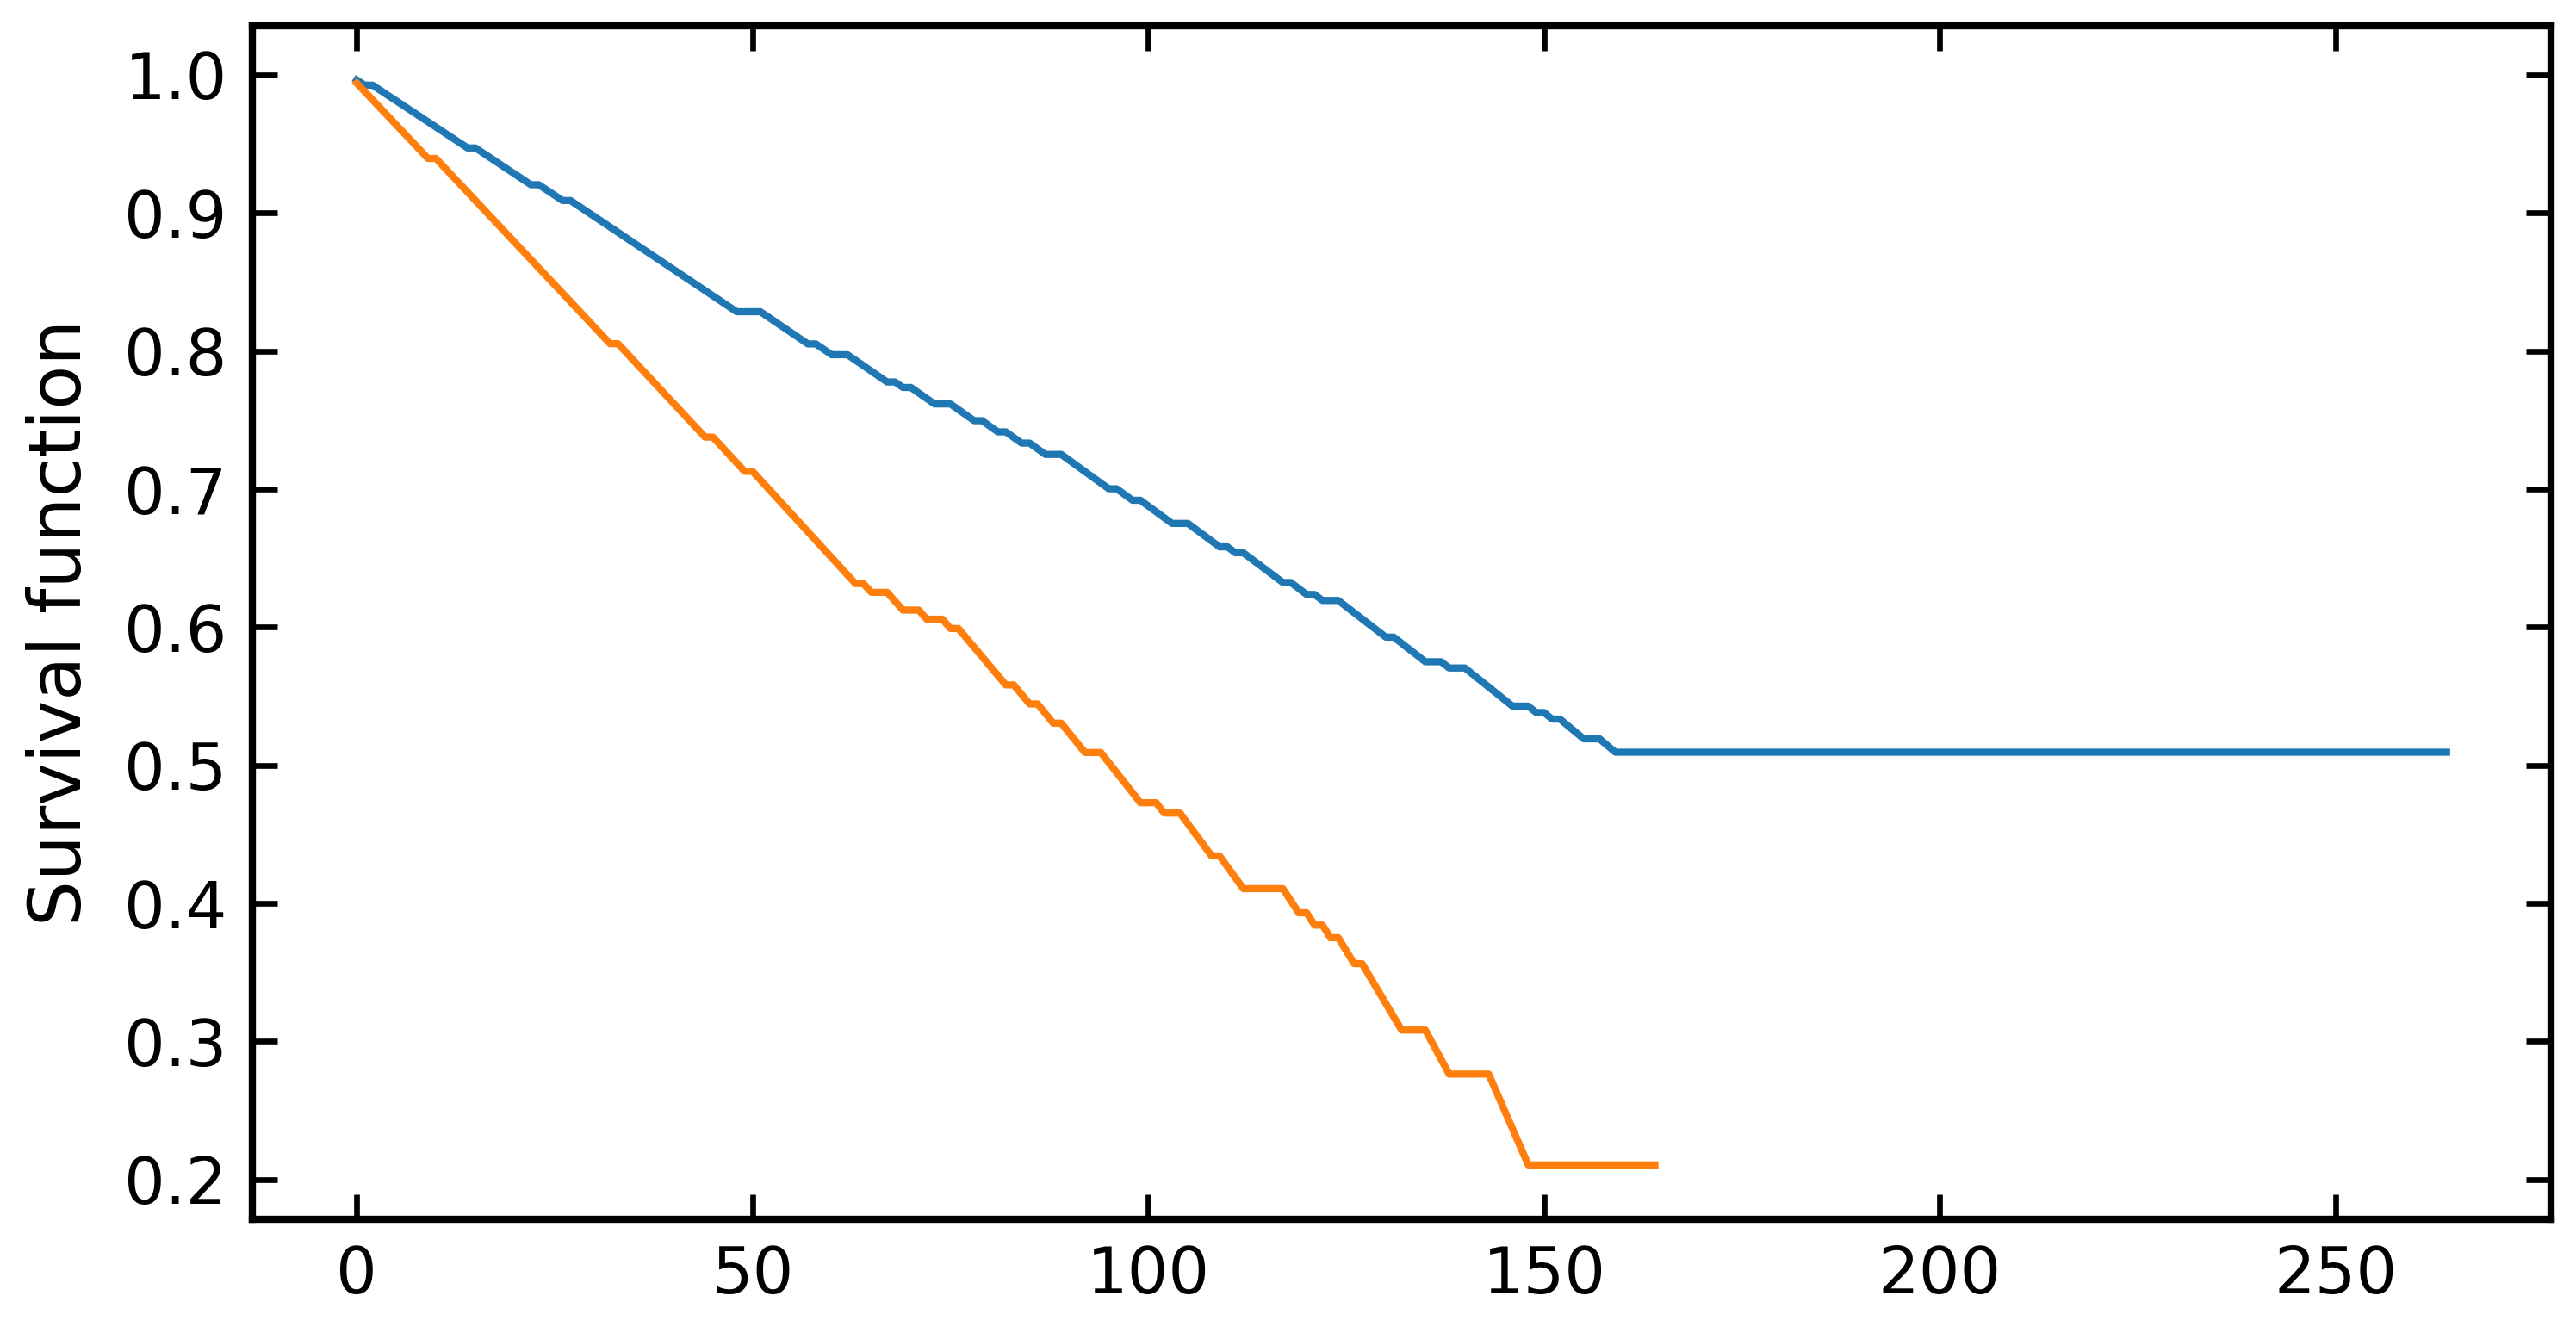

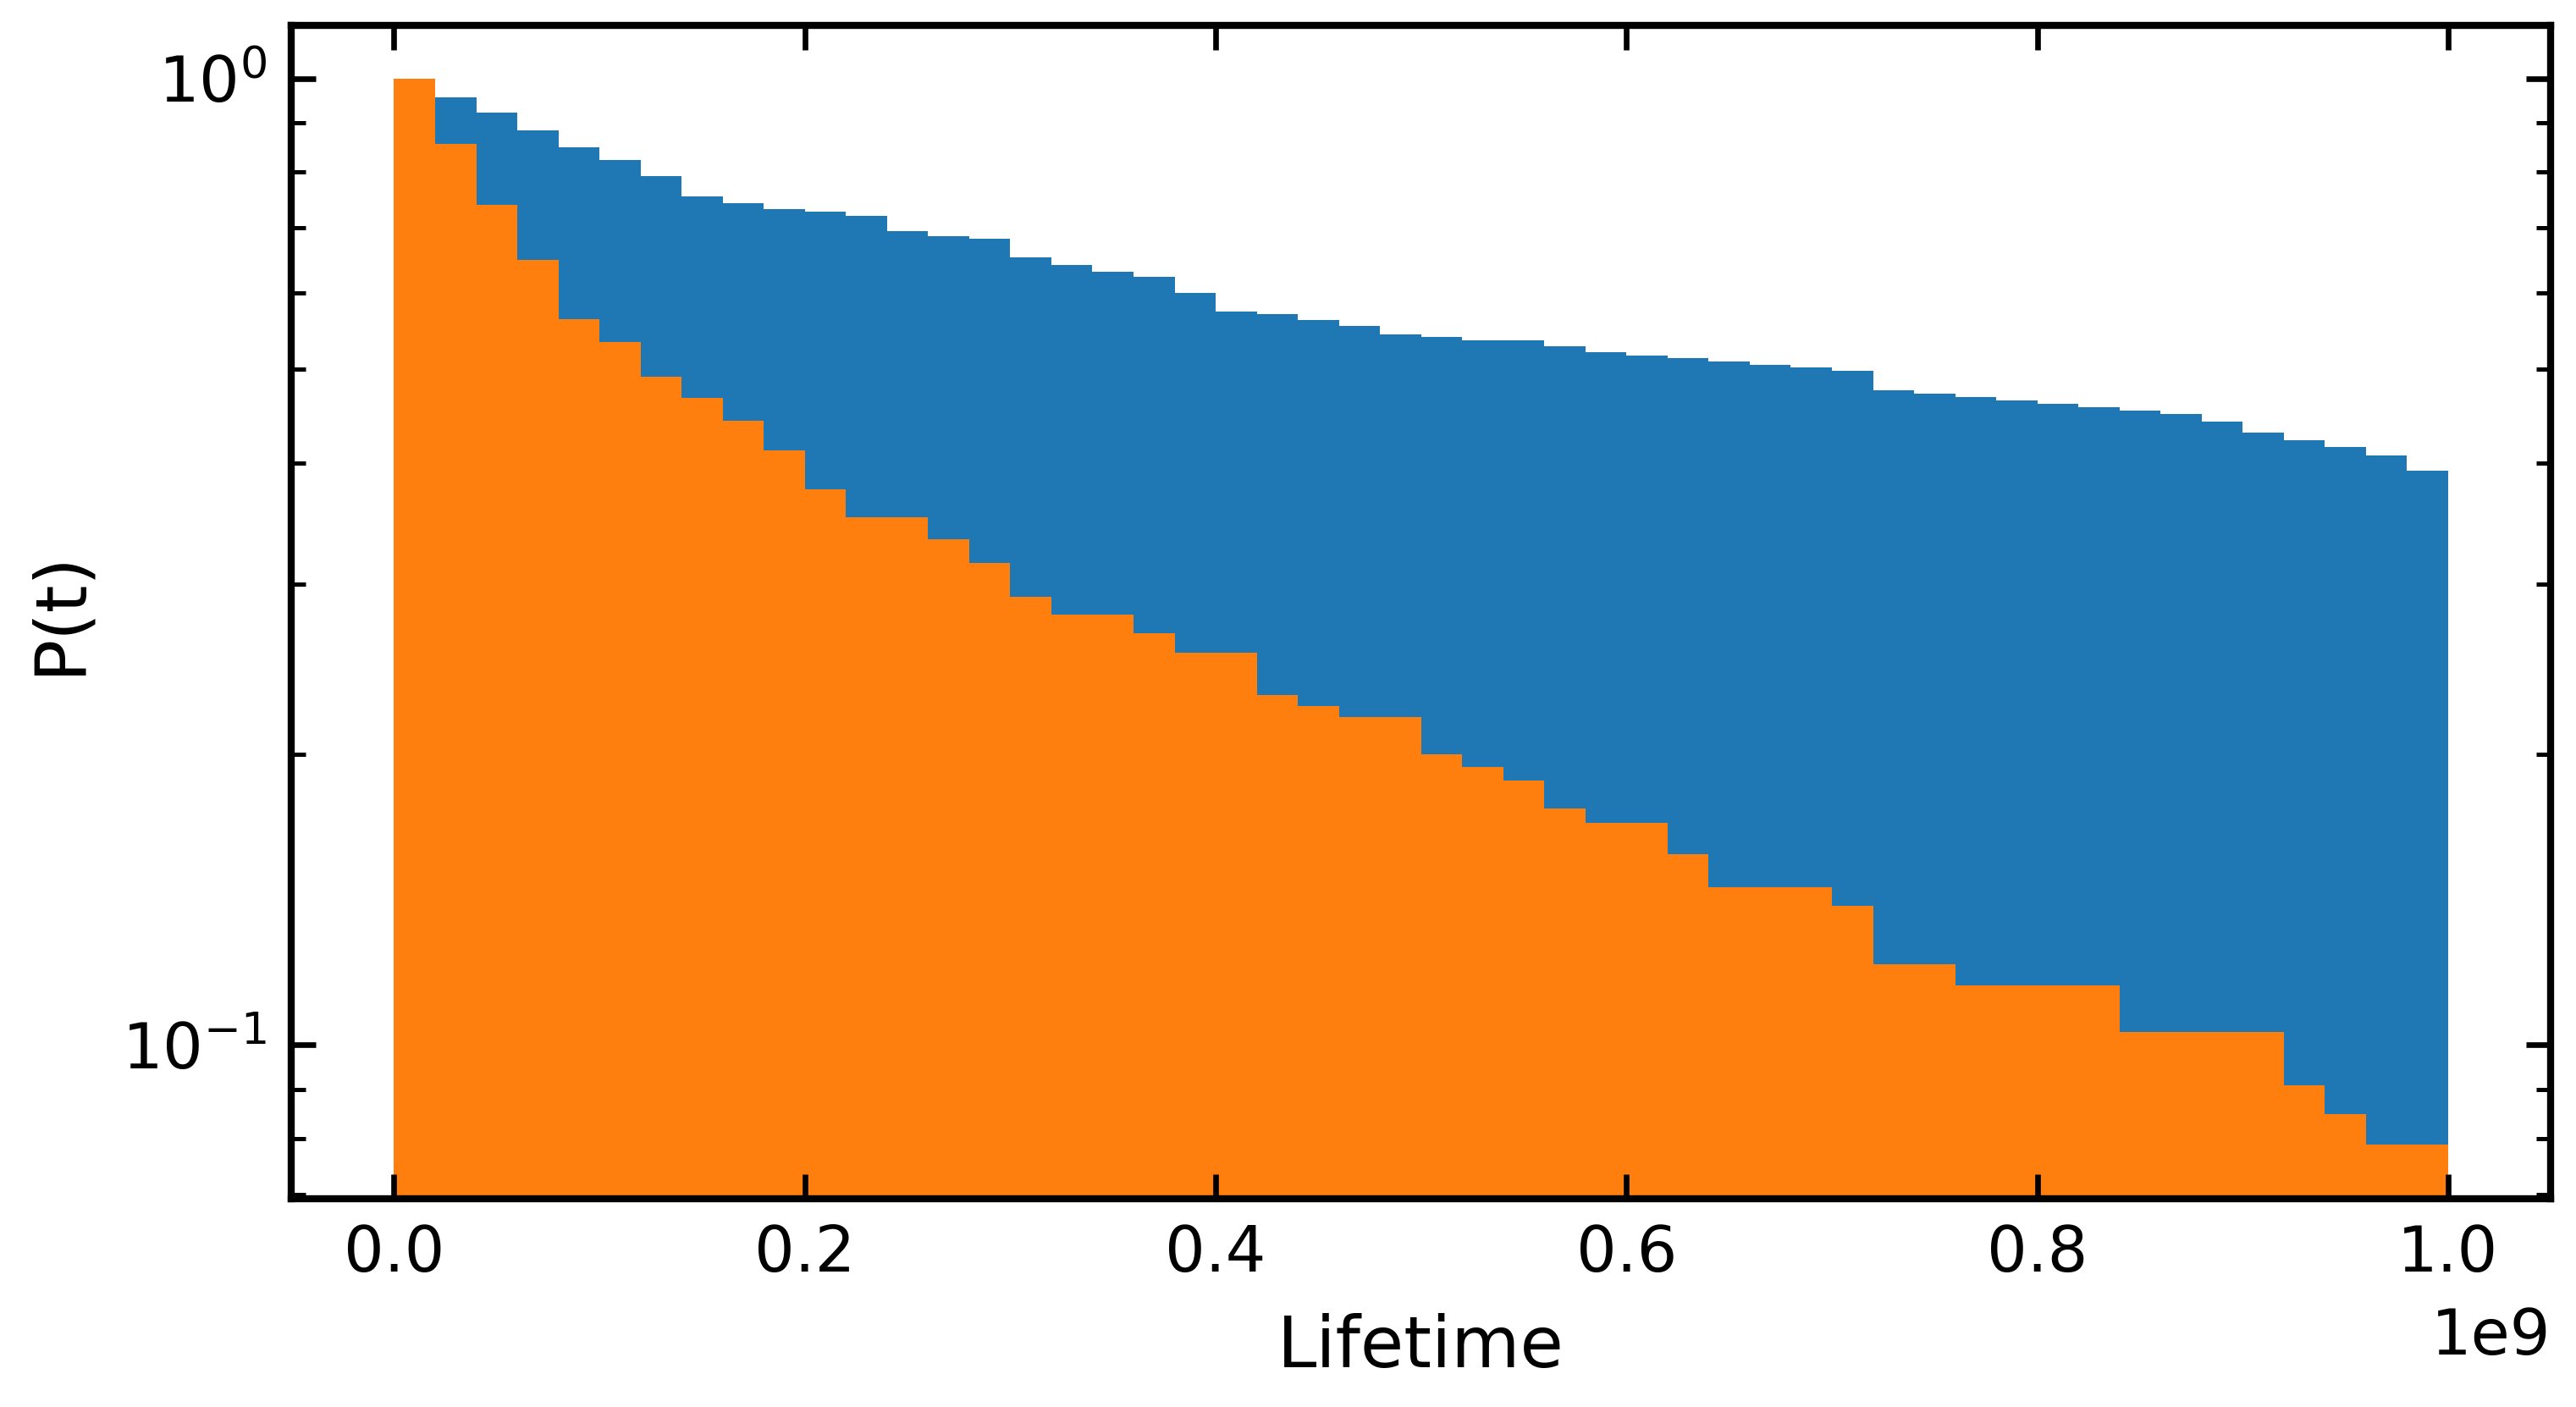

In [27]:
plt.plot(S_A)
plt.plot(S_B)
plt.ylabel('Survival function')
plt.show()

plt.hist(t_A, bins=50, density=True, cumulative=-1)
plt.hist(t_B, bins=50, density=True, cumulative=-1)
plt.yscale('log')
plt.xlabel('Lifetime')
plt.ylabel('P(t)')
plt.show()

# 3. Four states A/B × in/out

In [28]:
sim_type, n_k, n_p = 'ness', 2, 24
t_lens = timeline_lengths(sim_type, n_k, n_p)   # length of the timelines of every replica [MD steps]

tls = [hpt.load_timelines(timelines_file(sim_type, n_k, n_p, ss)) for ss in SIMS]

# nan: the replica has no transition along one edge of the cycle
dmus = [cycle_dmu_from_counts(hpt.compute_rates(tl)[2], CYCLE4, kT)[0] for tl in tls]
print('dmu per replica:', np.round(dmus, 2), '-> mean, SEM, n replicas', replica_mean_sem(dmus))

dmu per replica: [-6.15 -7.46   nan] -> mean, SEM, n replicas (-6.804180369700047, 0.6584306048330889, 2)


In [29]:
# all replicas merged (chains of replica k renumbered as chain + 200 k)
tl_merged = hpt.merge_replicas(tls, N_CHAINS)
rates, errors, counts, residence = hpt.compute_rates(tl_merged)
dmu, d_dmu = cycle_dmu_from_counts(counts, CYCLE4, kT)
fluxes = hpt.net_fluxes(counts, t_lens.mean(), N_CHAINS * len(SIMS))   # mean length x all chains = total chain time
print(f'dmu merged replicas = {dmu:.2f} +- {d_dmu:.2f} kJ/mol (Poisson)')
save_dmu_table(an_dir(sim_type, n_k, n_p) + f'dmu_4states_treshold{THRESHOLD}{TAG}.txt', {'4-state': (dmu, d_dmu, dmus)})
dict(counts), fluxes

dmu merged replicas = -7.54 +- 0.96 kJ/mol (Poisson)


({('B_out', 'B_in'): 9526,
  ('B_in', 'B_out'): 9647,
  ('B_out', 'A_out'): 123,
  ('A_out', 'A_in'): 18863,
  ('A_in', 'A_out'): 18745,
  ('A_in', 'B_in'): 382,
  ('B_in', 'A_in'): 254,
  ('A_out', 'B_out'): 5},
 {('B_out', 'B_in'): -2.016666666666667e-10,
  ('B_in', 'B_out'): 2.016666666666667e-10,
  ('B_out', 'A_out'): 1.9666666666666666e-10,
  ('A_out', 'A_in'): 1.9666666666666666e-10,
  ('A_in', 'A_out'): -1.9666666666666666e-10,
  ('A_in', 'B_in'): 2.1333333333333335e-10,
  ('B_in', 'A_in'): -2.1333333333333335e-10,
  ('A_out', 'B_out'): -1.9666666666666666e-10})

states : ['A_in', 'A_out', 'B_in', 'B_out']


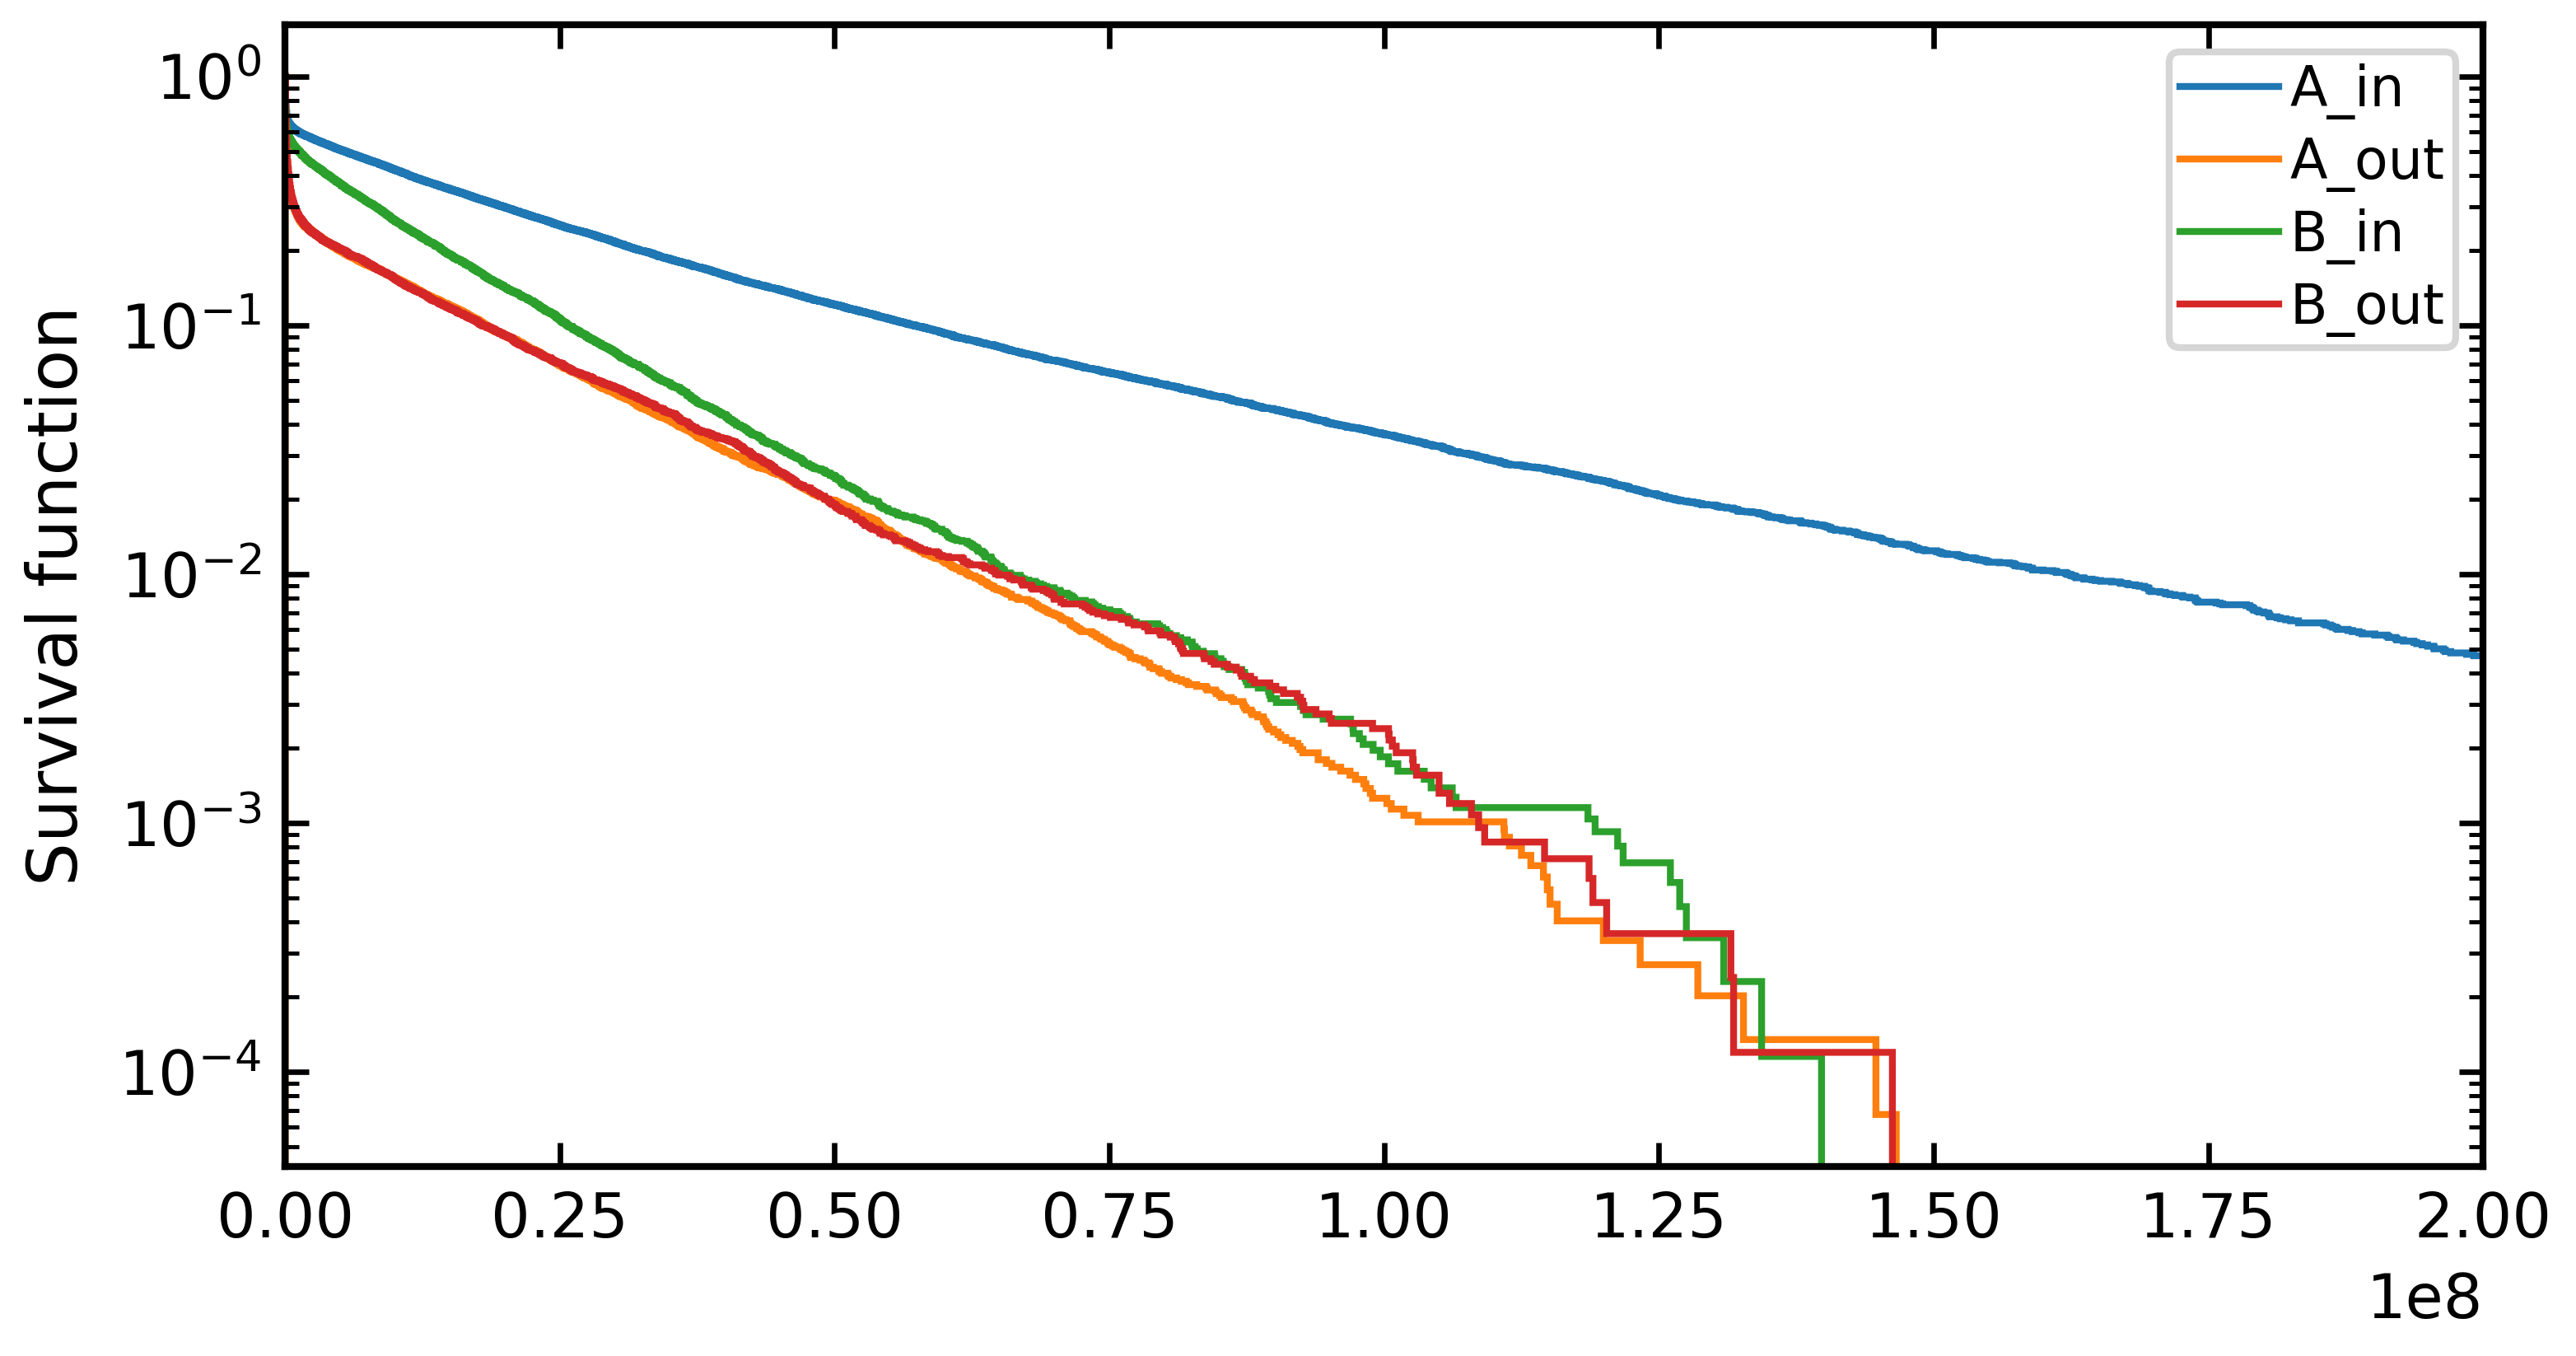

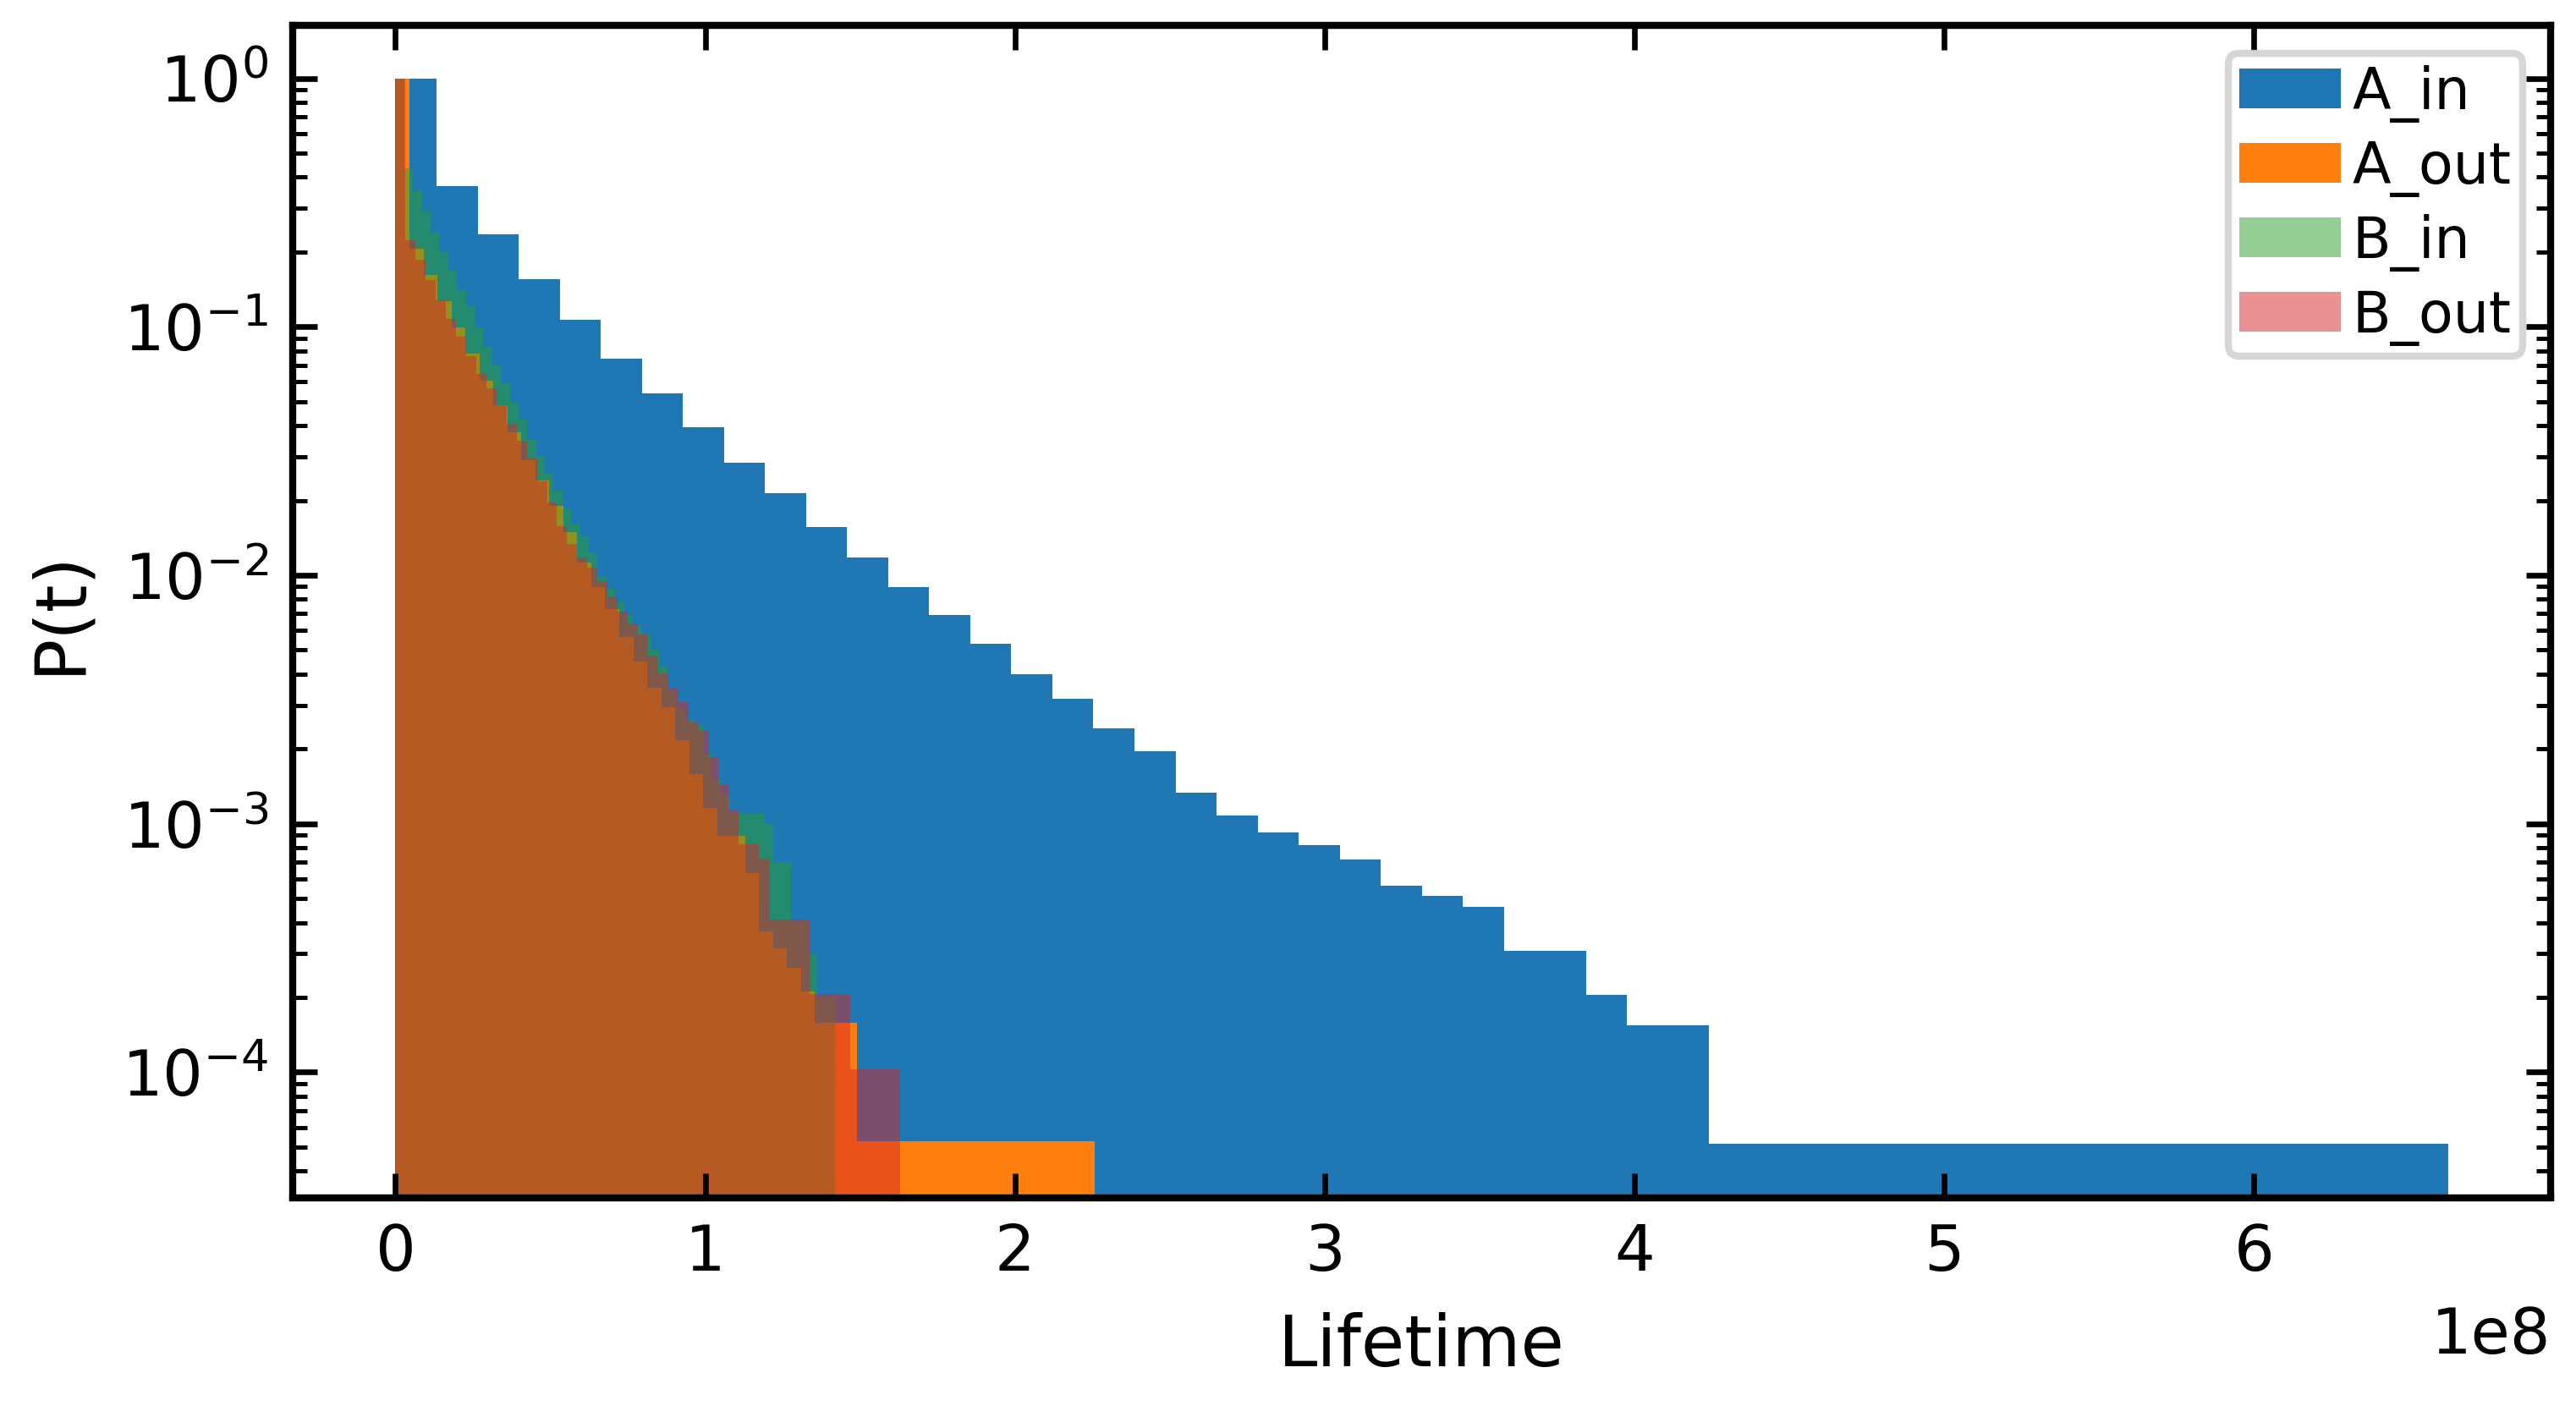

In [30]:
lts_4state, cens_4state = hpt.extract_lifetimes(tl_merged)
survival = {state: hpt.kaplan_meier(lts_4state[state], cens_4state[state]) for state in ['A_in', 'A_out', 'B_in', 'B_out']}

for state, (t, S) in survival.items():
    plt.stairs(S, np.append([0], t), label=state)
plt.yscale('log')
plt.ylabel('Survival function')
plt.xlim(0, 2e8)
plt.legend()
plt.show()

for state, alpha in [('A_in', 1), ('A_out', 1), ('B_in', 0.5), ('B_out', 0.5)]:
    plt.hist(survival[state][0], bins=50, density=True, cumulative=-1, label=state, alpha=alpha)
plt.yscale('log')
plt.xlabel('Lifetime')
plt.ylabel('P(t)')
plt.legend()
plt.show()

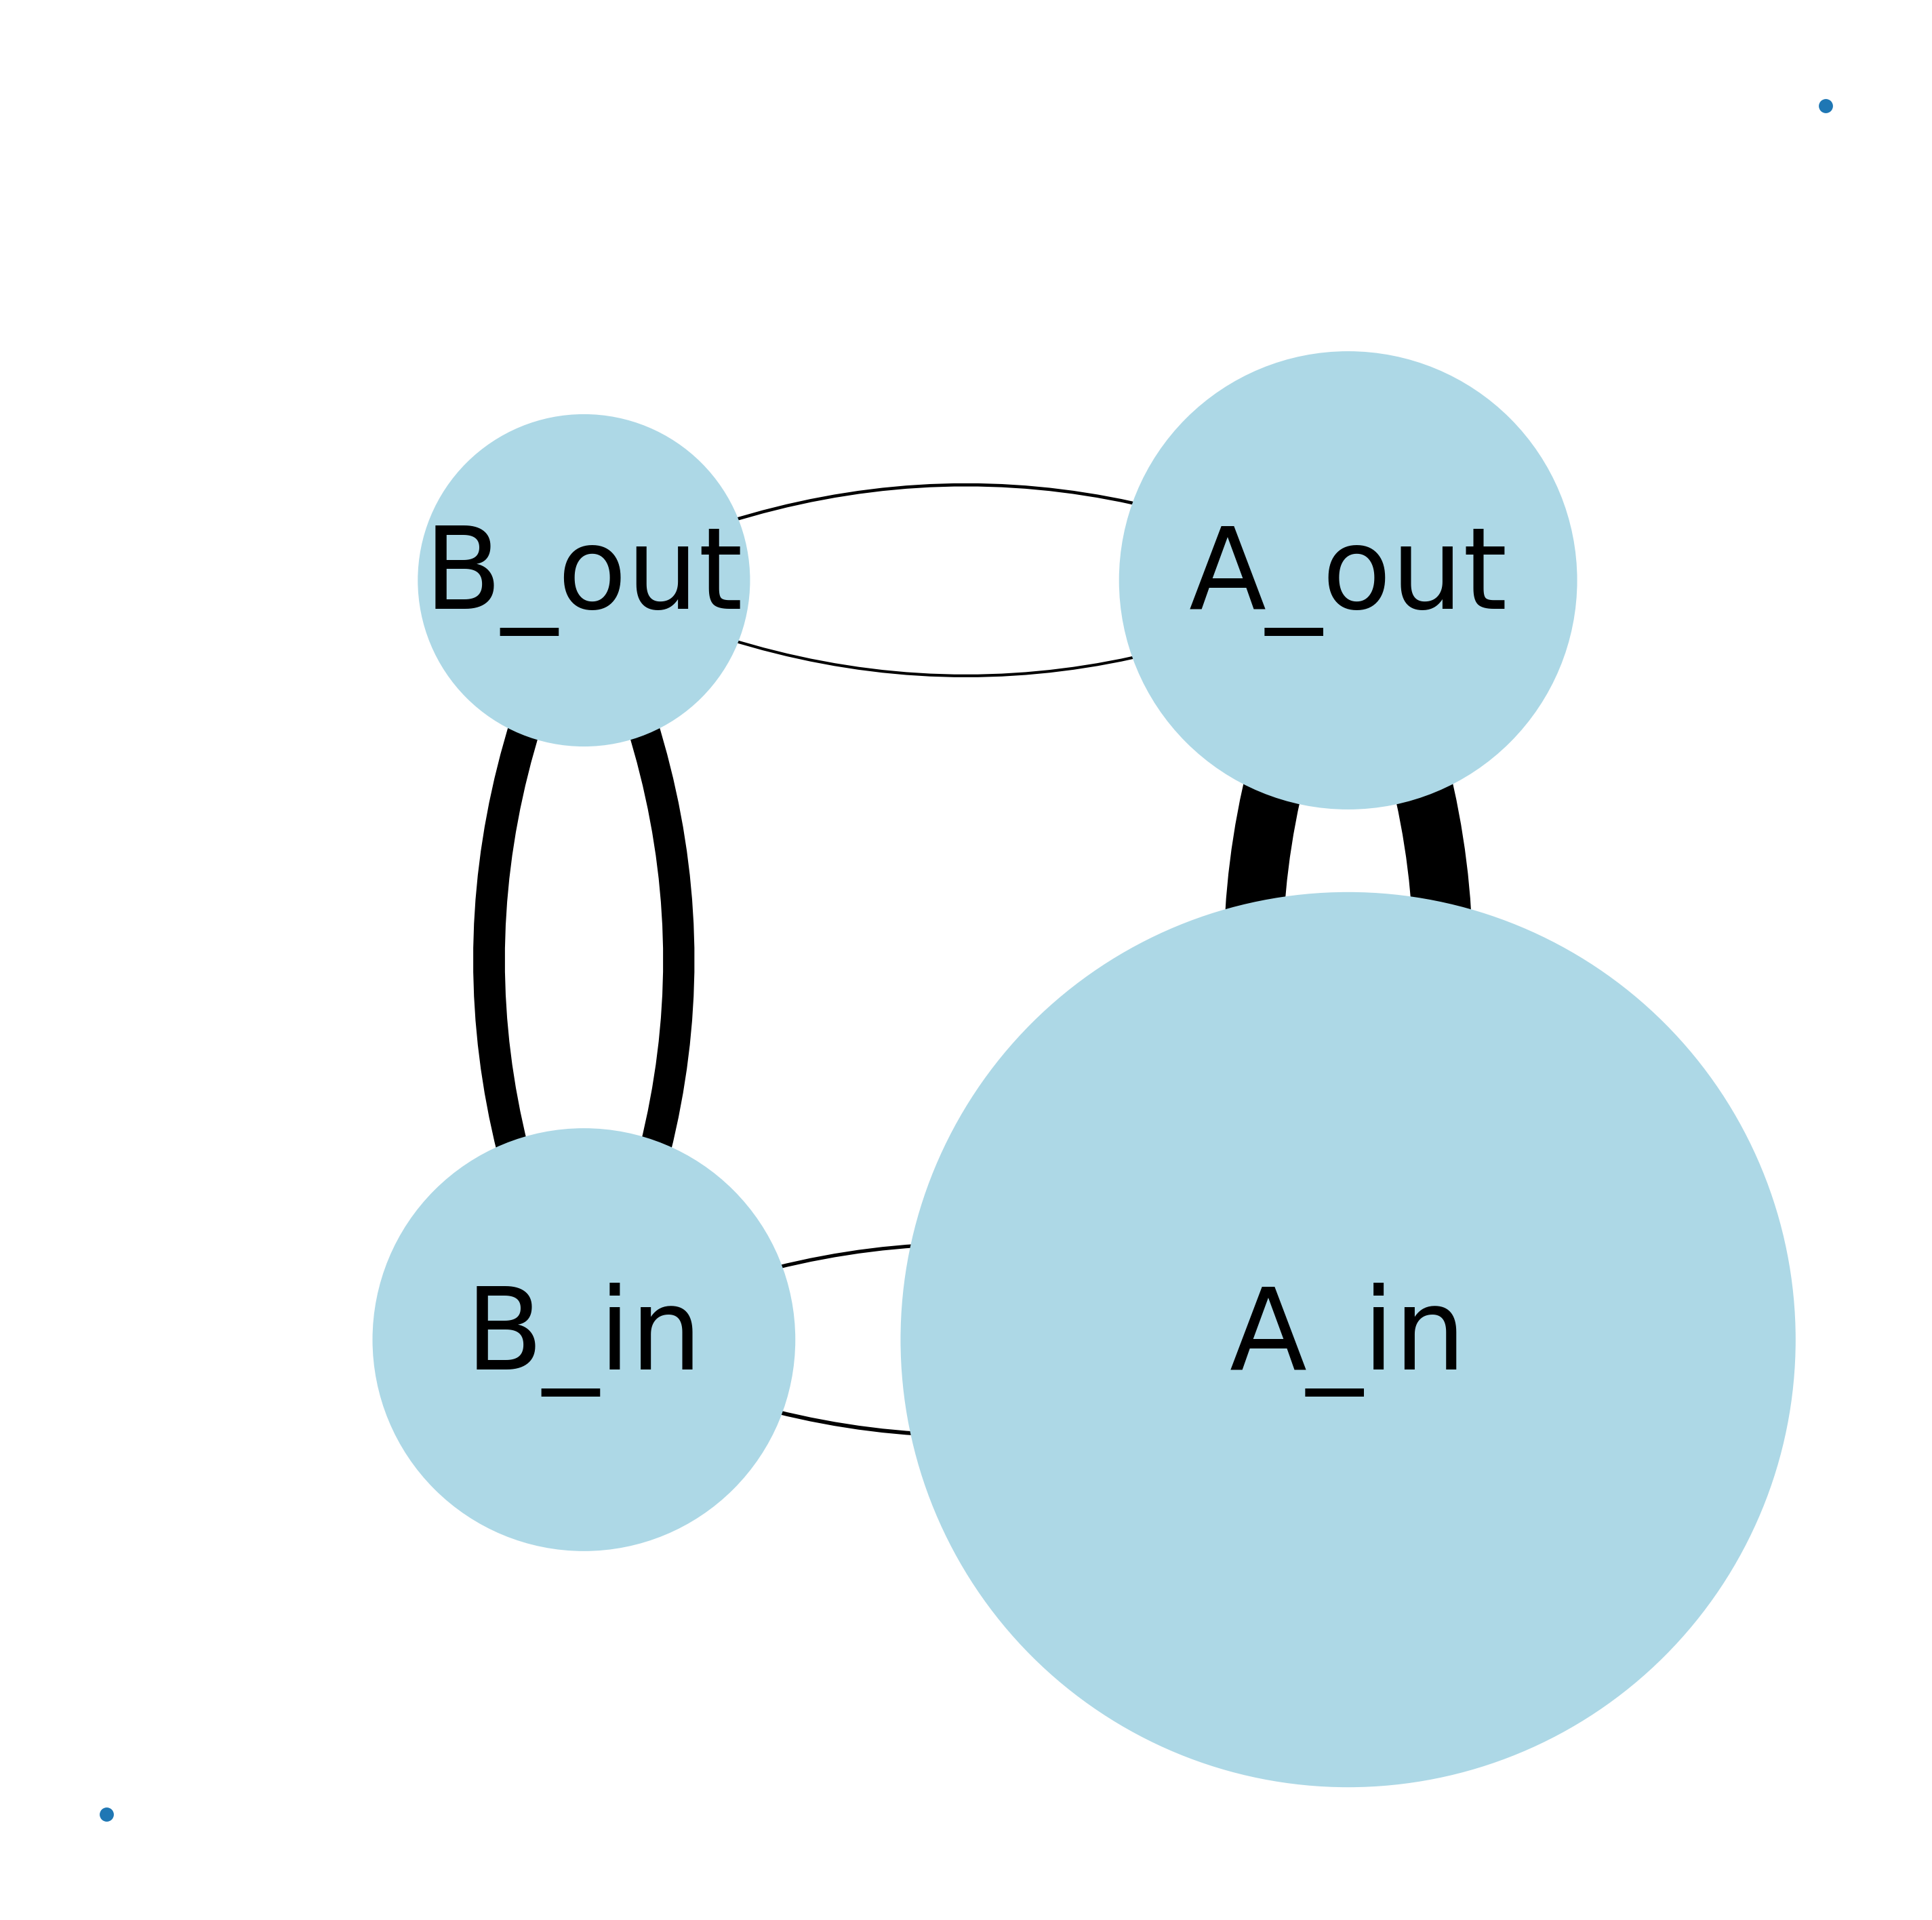

In [31]:
# 4-state network: node size ~ residence time, edge width ~ number of transitions (merged replicas)
states4 = ['A_out', 'A_in', 'B_in', 'B_out']
edges4 = [(0, 1), (0, 3), (1, 0), (1, 2), (2, 1), (2, 3), (3, 2), (3, 0)]

G = nx.DiGraph()
G.add_nodes_from(range(4))
G.add_edges_from(edges4)
widths = np.array([counts.get((states4[i], states4[j]), 0) for i, j in edges4], dtype=float)
widths = 0.5 + 10 * (widths - widths.min()) / (widths.max() - widths.min())

pos = dict(enumerate(np.array([(1, 1), (1, -1), (-1, -1), (-1, 1)]) * 200))
plt.figure(figsize=(6, 6))
plt.plot([-450, 450], [-450, 450], '.')
nx.draw(G, pos, with_labels=True, arrowstyle='-', connectionstyle='arc3,rad=-0.25', labels=dict(enumerate(states4)),
        arrowsize=80, node_color='lightblue', node_size=np.array([residence[s] for s in states4]) / 15000000, font_size=20, width=0.1)
nx.draw_networkx_edges(G, pos, edgelist=edges4, arrowstyle='-', connectionstyle='arc3,rad=-0.25', arrowsize=30,
                       node_size=0, width=widths)
# savefig(path_drop_fr_pl + f'{drop_name(sim_type, n_k, n_p)}/cycle_treshold{THRESHOLD}{TAG}')

## Turnover
Net phosphorylations by the kinases per chain per step, divided by the net B$_{in}$ → B$_{out}$ flux: phosphorylations per cycle. Each phosphorylation cycle consumes $-\Delta\mu_k + \Delta\mu_p$ = 48 kJ/mol.

In [32]:
net_phospho_k = net_dephospho_p = 0
for ss, t_len in zip(SIMS, t_lens):
    _, _, contacts_file, _ = sim_files(sim_type, n_k, n_p, ss)
    c = np.loadtxt(contacts_file)
    c = c[(c[:, 0] > T_THERM) & (c[:, 0] <= T_THERM + t_len)]
    c_k = c[c[:, 5] < n_k]      # enzyme ids: kinases first
    c_p = c[c[:, 5] >= n_k]
    net_phospho_k += np.sum(c_k[:, 2] == 1) - np.sum(c_k[:, 2] == -1)
    net_dephospho_p += np.sum(c_p[:, 2] == -1) - np.sum(c_p[:, 2] == 1)

phospho_rate = net_phospho_k / N_CHAINS / t_lens.sum()      # per chain per MD step
n_phospho_per_cycle = phospho_rate / fluxes[('B_in', 'B_out')]
resolved_fraction = -dmu / n_phospho_per_cycle / 48.0
phospho_rate, n_phospho_per_cycle, resolved_fraction

(1.01e-08, 50.08264462809917, 0.003138483896115332)

# 4. Six states A/B × in/interface/out

In [33]:
sim_type, n_k, n_p = 'ness', 2, 24

states6 = ['A_out', 'A_interface', 'A_in', 'B_in', 'B_interface', 'B_out']
edges6 = [(0, 1), (0, 2), (0, 5), (1, 0), (1, 2), (1, 4), (2, 0), (2, 1), (2, 3),
          (3, 2), (3, 4), (3, 5), (4, 1), (4, 3), (4, 5), (5, 0), (5, 3), (5, 4)]

tls6 = [hpt.load_timelines(timelines_file(sim_type, n_k, n_p, ss, six_states=True)) for ss in SIMS]
per_replica = [hpt.compute_rates(tl) for tl in tls6]
counts6_merged = hpt.compute_rates(hpt.merge_replicas(tls6, N_CHAINS))[2]

# replica averages; errors = standard error of the transition counts
residence = {s: np.mean([res[3][s] for res in per_replica]) for s in states6}
rates, counts, errors = {}, {}, {}
for i, j in edges6:
    key = (states6[i], states6[j])
    counts[key] = np.mean([res[2][key] for res in per_replica])
    rates[key] = np.nanmean([res[0].get(key, 0.0) for res in per_replica])
    errors[key] = mean_err([res[2][key] for res in per_replica])[1]
counts, errors

({('A_out', 'A_interface'): 4251.0,
  ('A_out', 'A_in'): 2036.6666666666667,
  ('A_out', 'B_out'): 1.6666666666666667,
  ('A_interface', 'A_out'): 4242.0,
  ('A_interface', 'A_in'): 193808.33333333334,
  ('A_interface', 'B_interface'): 69.33333333333333,
  ('A_in', 'A_out'): 2006.3333333333333,
  ('A_in', 'A_interface'): 193801.66666666666,
  ('A_in', 'B_in'): 57.666666666666664,
  ('B_in', 'A_in'): 13.666666666666666,
  ('B_in', 'B_interface'): 40348.666666666664,
  ('B_in', 'B_out'): 1080.0,
  ('B_interface', 'A_interface'): 71.0,
  ('B_interface', 'B_in'): 40315.0,
  ('B_interface', 'B_out'): 2135.6666666666665,
  ('B_out', 'A_out'): 41.0,
  ('B_out', 'B_in'): 1069.0,
  ('B_out', 'B_interface'): 2106.3333333333335},
 {('A_out', 'A_interface'): 67.88470618138767,
  ('A_out', 'A_in'): 34.22637059994011,
  ('A_out', 'B_out'): 0.8819171036881968,
  ('A_interface', 'A_out'): 78.42831121476478,
  ('A_interface', 'A_in'): 2213.950039584854,
  ('A_interface', 'B_interface'): 3.3333333333333

In [34]:
CYCLES6 = {
    'full':      ['A_out', 'A_interface', 'A_in', 'B_in', 'B_interface', 'B_out'],
    'interface': ['A_interface', 'A_in', 'B_in', 'B_interface'],
    'out':       ['A_out', 'A_interface', 'B_interface', 'B_out'],
    'A':         ['A_out', 'A_interface', 'A_in'],
    'B':         ['B_out', 'B_interface', 'B_in'],
}
# merged replicas: Poisson error; per replica: nan if an edge of the cycle has no transitions
dmus6, results6 = {}, {}
for name, cycle in CYCLES6.items():
    dmus6[name] = cycle_dmu_from_counts(counts6_merged, cycle, kT)
    reps = [cycle_dmu_from_counts(res[2], cycle, kT)[0] for res in per_replica]
    mean, sem, n_rep = replica_mean_sem(reps)
    results6[name] = (*dmus6[name], reps)
    print(f'dmu {name:9s} = {dmus6[name][0]:6.2f} +- {dmus6[name][1]:.2f} kJ/mol (merged, Poisson) | '
          f'replicas {np.round(reps, 2)} -> {mean:.2f} +- {sem:.2f} (SEM, n={n_rep})')
save_dmu_table(an_dir(sim_type, n_k, n_p) + f'dmu_6states_treshold{THRESHOLD}{TAG}.txt', results6)

dmu full      =   9.68 +- 1.02 kJ/mol (merged, Poisson) | replicas [7.47 9.58  nan] -> 8.53 +- 1.05 (SEM, n=2)
dmu interface =   3.04 +- 0.41 kJ/mol (merged, Poisson) | replicas [1.98 2.97 4.32] -> 3.09 +- 0.68 (SEM, n=3)
dmu out       =   6.64 +- 0.97 kJ/mol (merged, Poisson) | replicas [5.49 6.61  nan] -> 6.05 +- 0.56 (SEM, n=2)
dmu A         =  -0.03 +- 0.05 kJ/mol (merged, Poisson) | replicas [ 0.01 -0.1   0.01] -> -0.03 +- 0.03 (SEM, n=3)
dmu B         =  -0.01 +- 0.06 kJ/mol (merged, Poisson) | replicas [ 0.02 -0.07  0.03] -> -0.01 +- 0.03 (SEM, n=3)


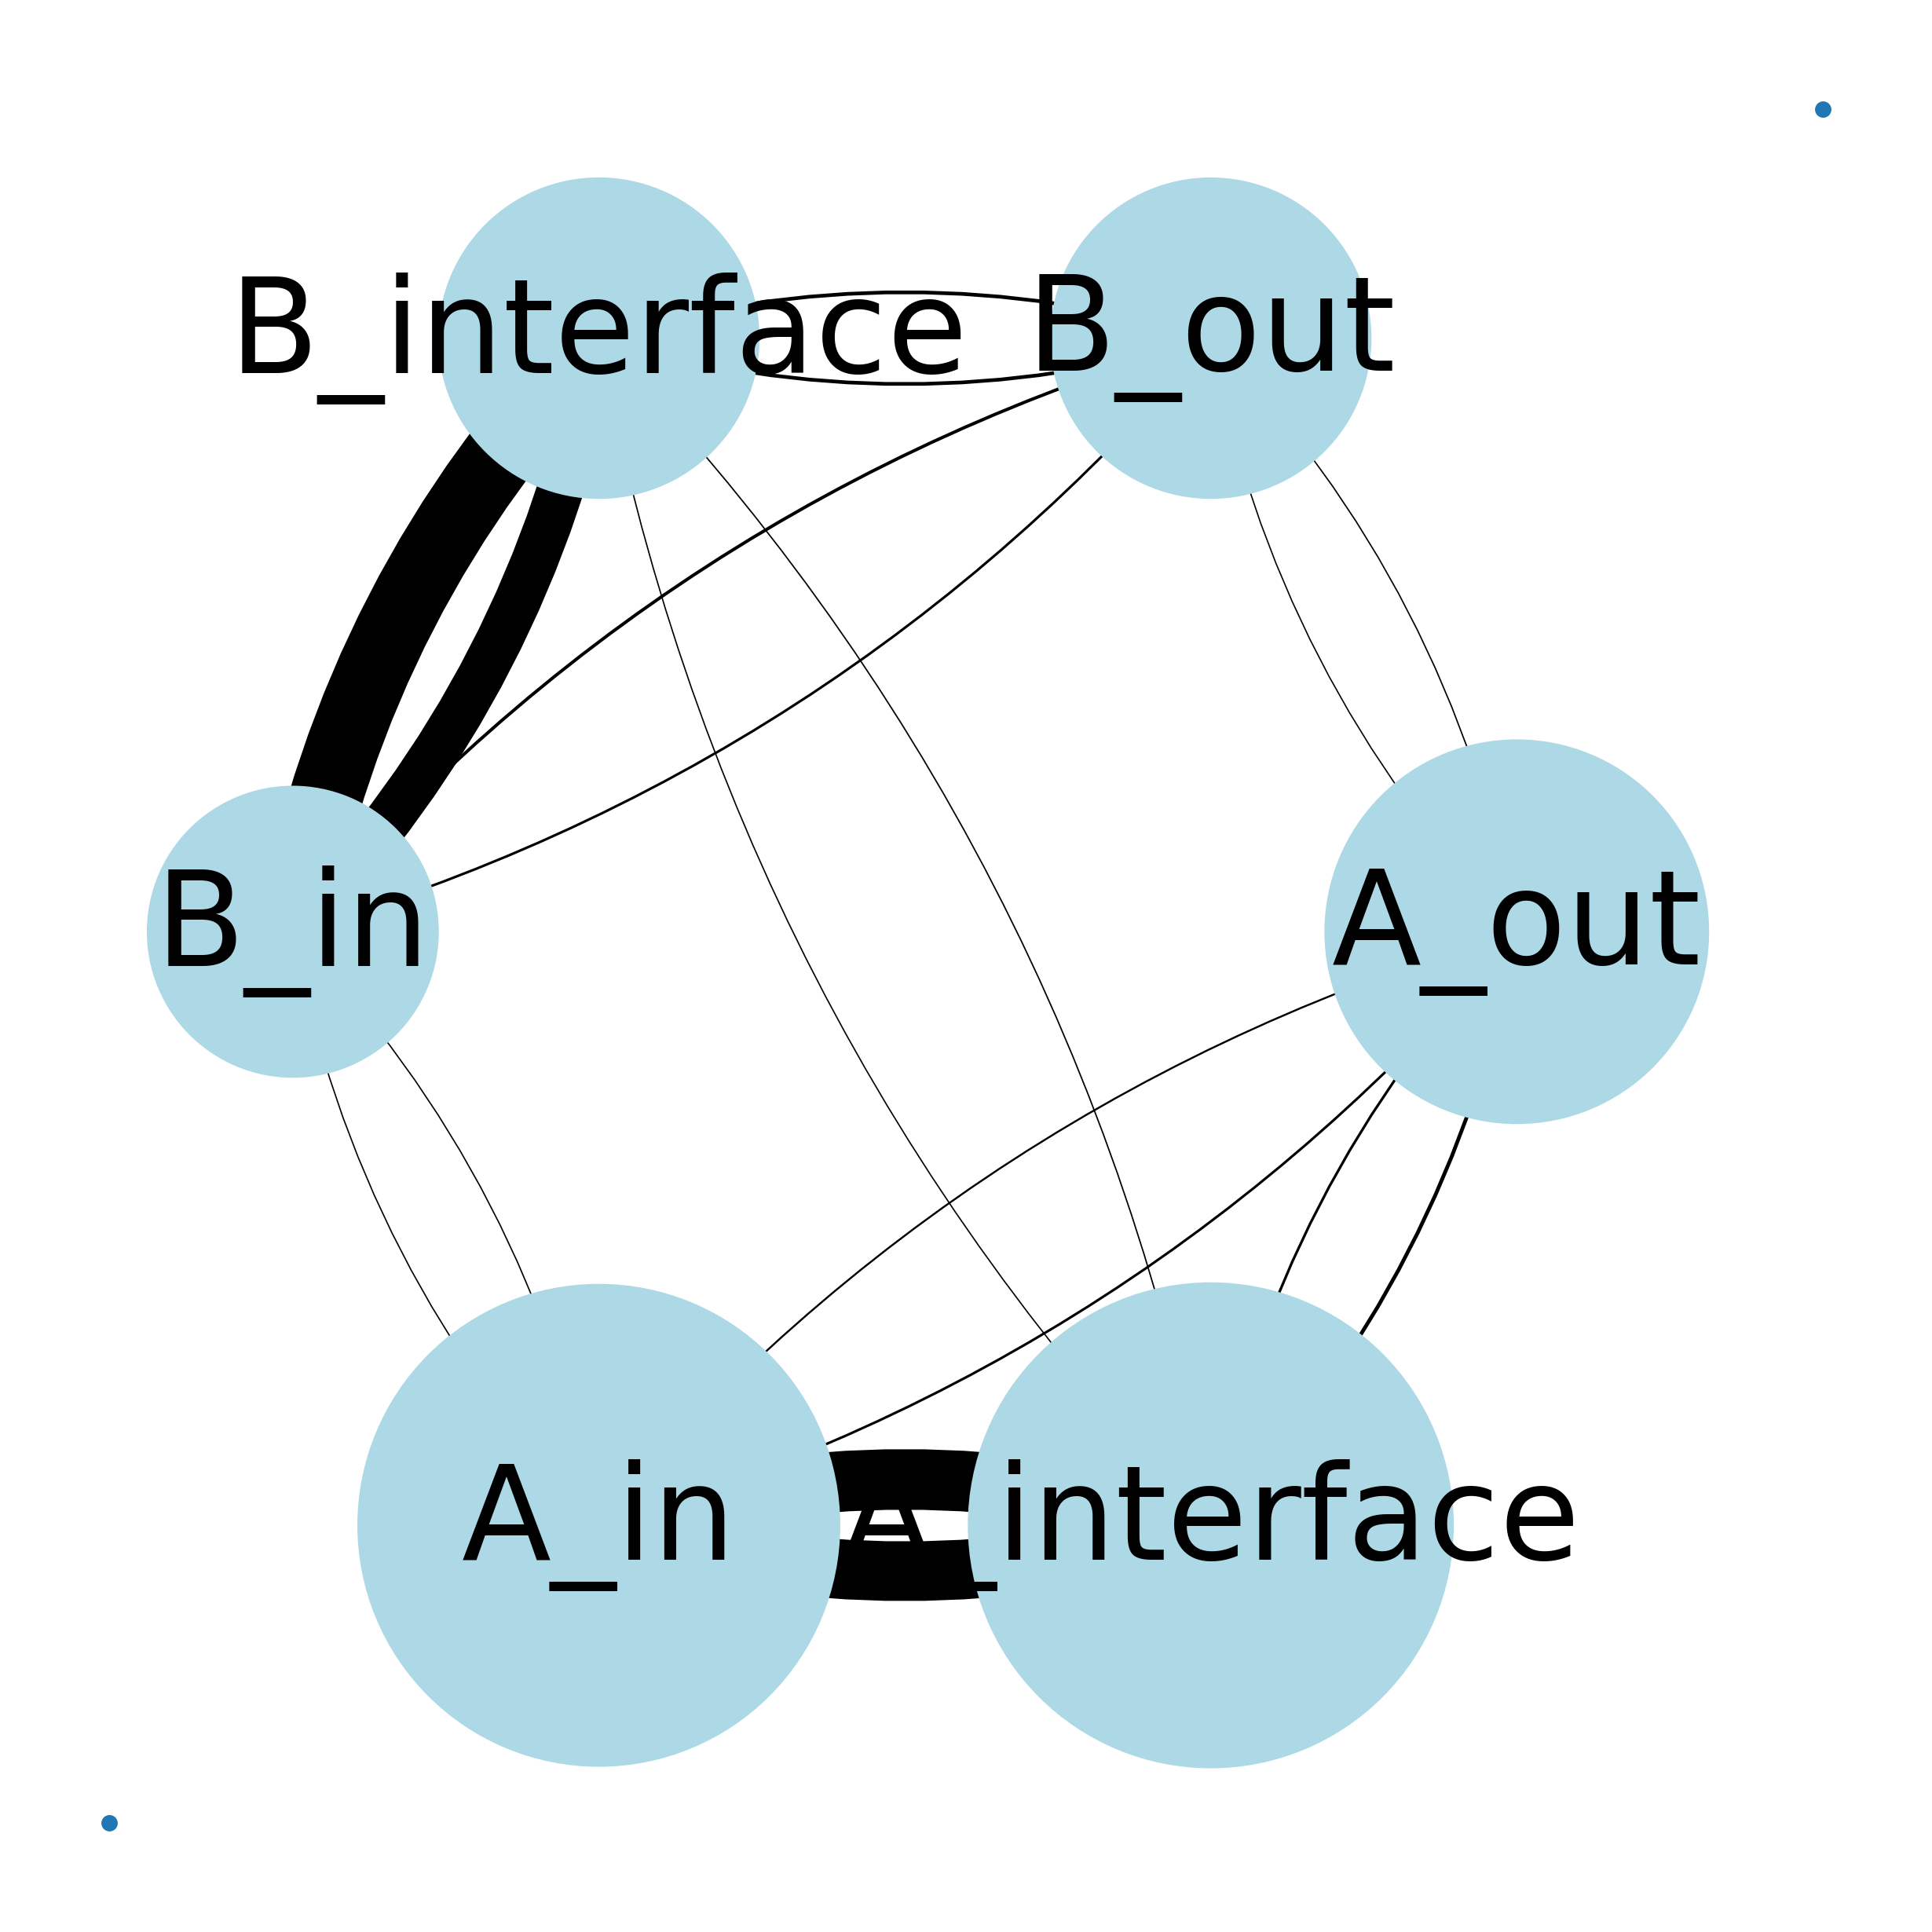

In [35]:
# 6-state network: node size ~ residence time, edge width ~ rate
G = nx.DiGraph()
G.add_nodes_from(range(6))
for i in range(6):
    G.add_edge(i, (i + 1) % 6)
    G.add_edge((i + 1) % 6, i)

widths = np.array([rates[(states6[i], states6[j])] for i, j in edges6])
widths = 0.2 + 11 * (widths - widths.min()) / (widths.max() - widths.min())
nodesize = np.array([residence[s] for s in states6]) / 15000000

angles = np.pi * np.array([0, -1/3, -2/3, 1, 2/3, 1/3])
pos = dict(enumerate(np.column_stack((np.cos(angles), np.sin(angles)))))

plt.figure(figsize=(4, 4))
nx.draw(G, pos, with_labels=True, arrowstyle='-', connectionstyle='arc3,rad=-0.25', labels=dict(enumerate(states6)),
        arrowsize=80, node_color='lightblue', node_size=nodesize + 1200, font_size=20, width=0)
nx.draw_networkx_edges(G, pos, edgelist=edges6, arrowstyle='-', connectionstyle='arc3,rad=-0.15',
                       arrowsize=50, node_size=nodesize * 10000 + 1000, width=widths)
plt.plot([-1.3, 1.5], [-1.3, 1.2], '.')   # enlarges the axes
savefig(path_drop_fr_pl + f'cycle_6states_{sim_type}_treshold{THRESHOLD}{TAG}')

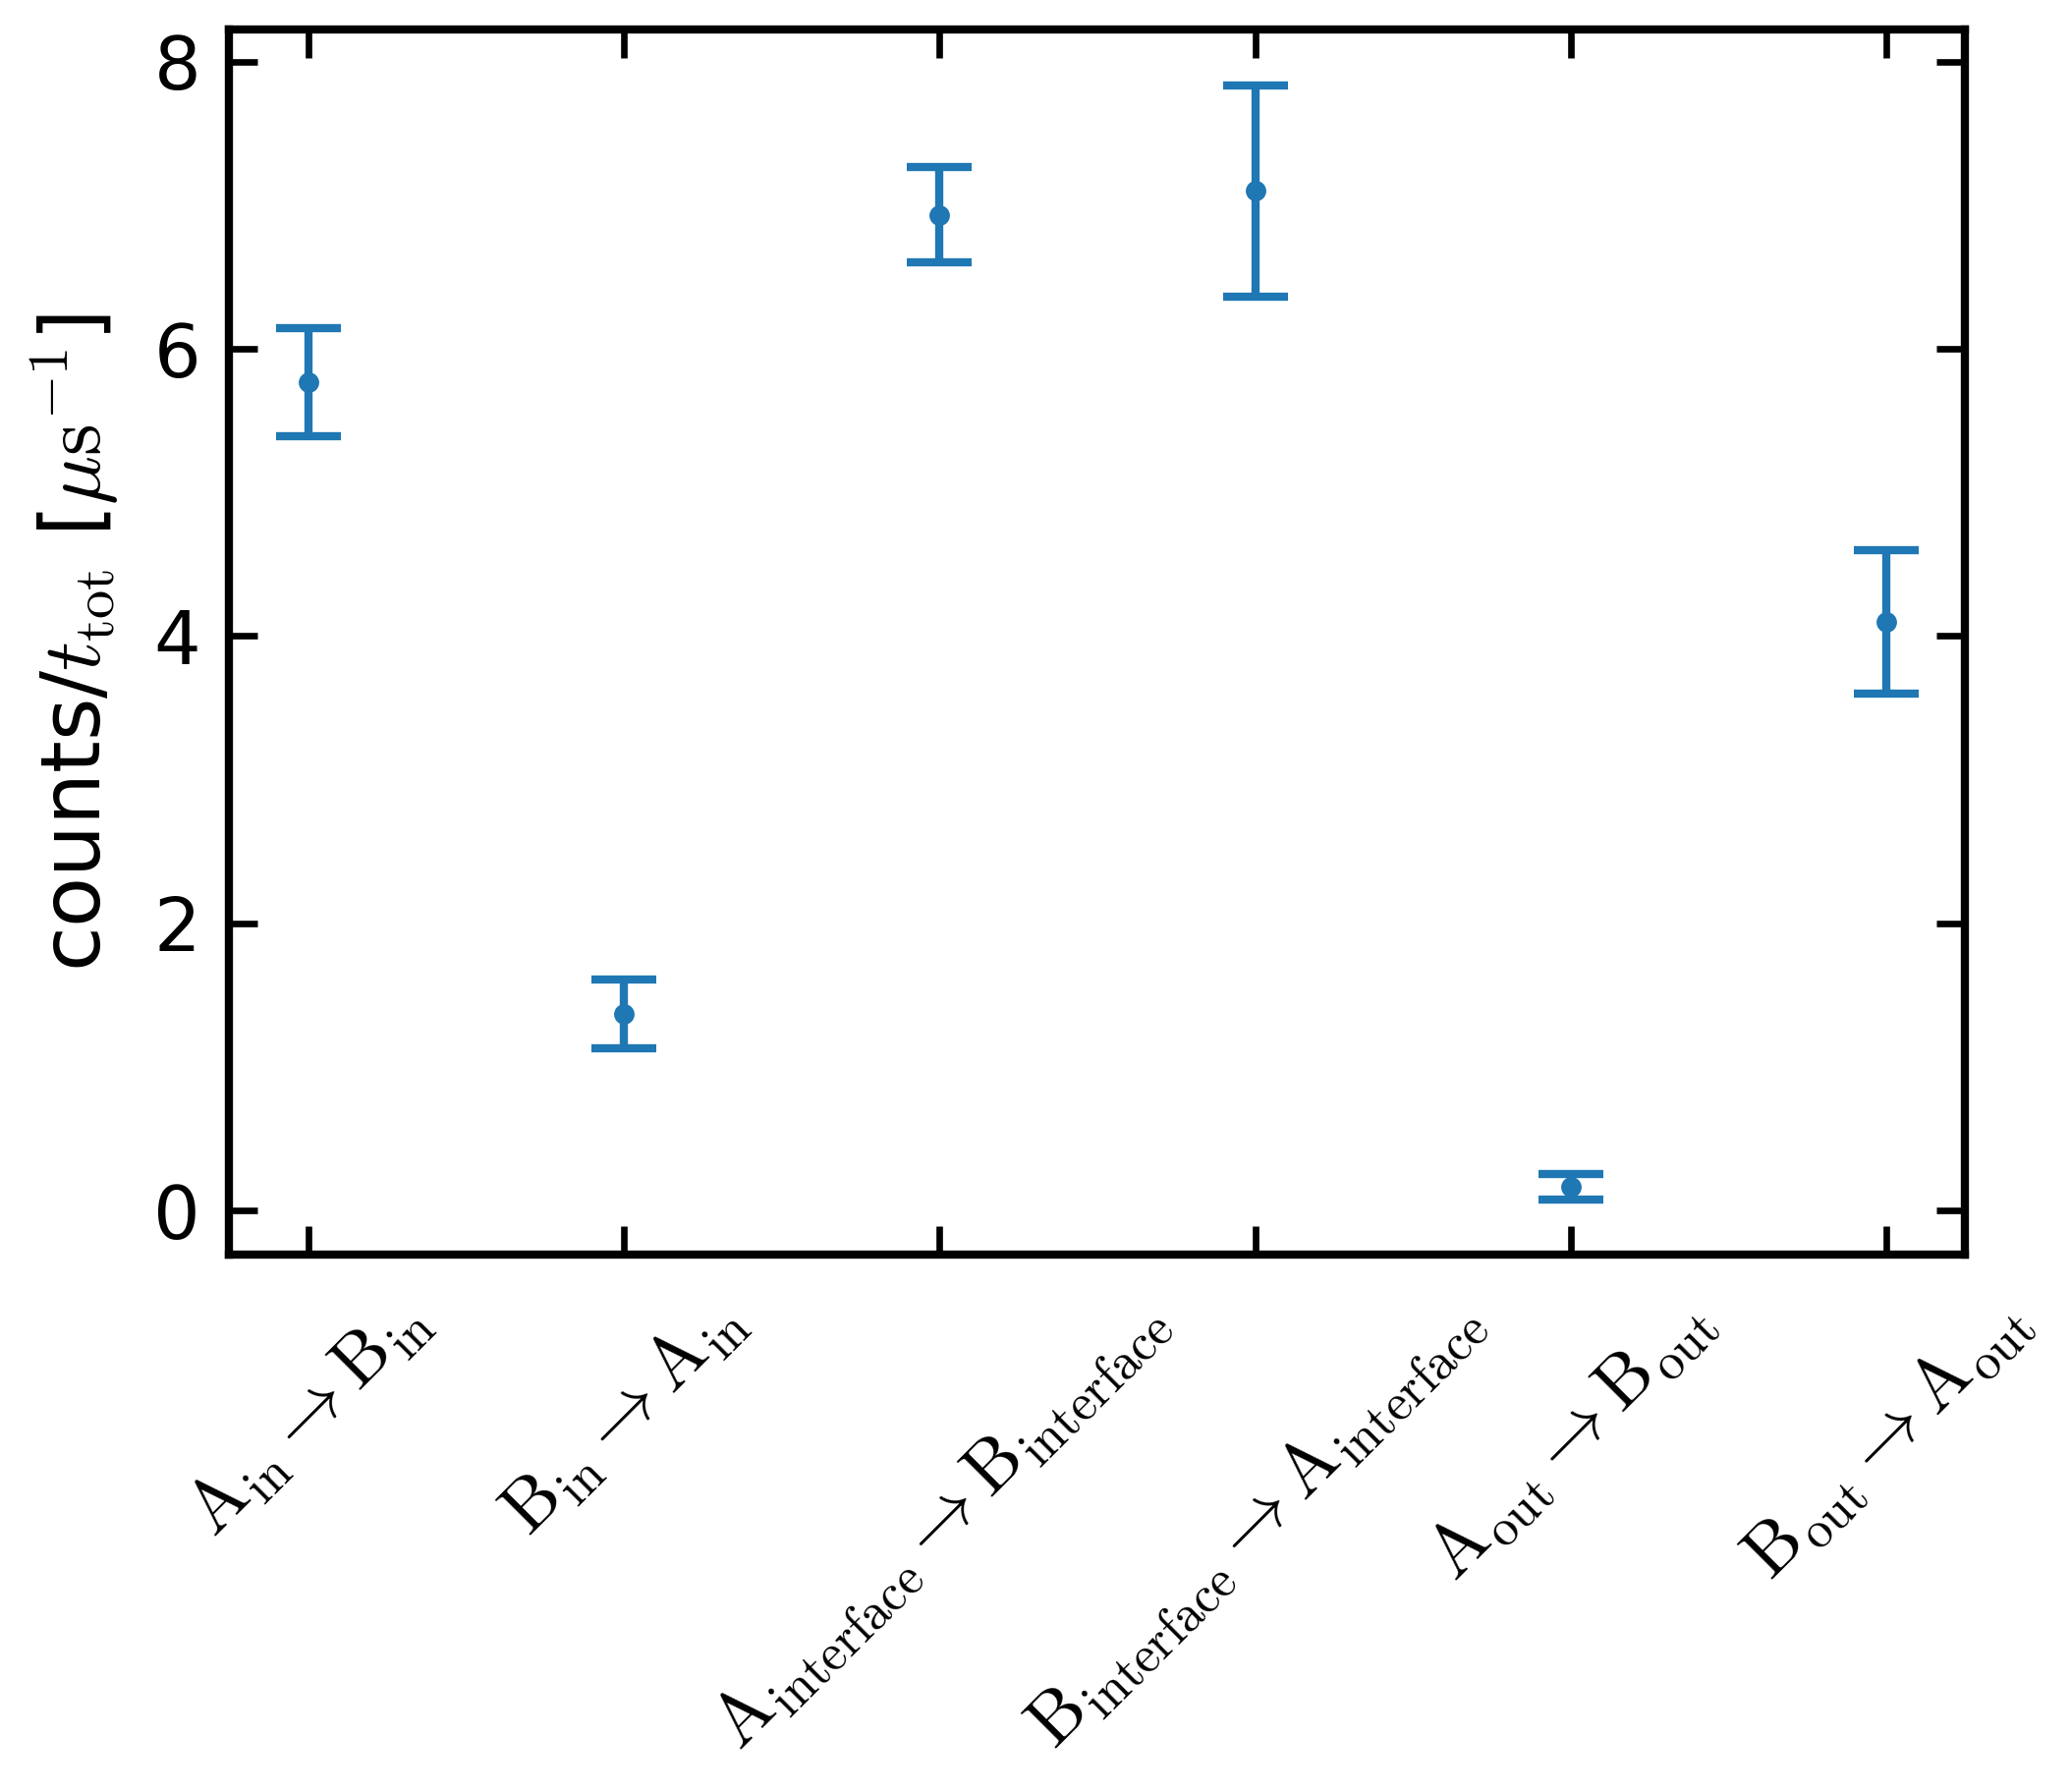

In [36]:
t_us = steps_to_us(timeline_lengths(sim_type, n_k, n_p).mean())   # mean length of the timelines [us] (counts are replica means)
plt.figure(figsize=(3.8, 2.7))
transitions = [('A_in', 'B_in'), ('B_in', 'A_in'), ('A_interface', 'B_interface'), ('B_interface', 'A_interface'),
               ('A_out', 'B_out'), ('B_out', 'A_out')]
labels = [r'$\mathrm{A_{in} \rightarrow B_{in}}$', r'$\mathrm{B_{in} \rightarrow A_{in}}$',
          r'$\mathrm{A_{interface} \rightarrow B_{interface}}$', r'$\mathrm{B_{interface} \rightarrow A_{interface}}$',
          r'$\mathrm{A_{out} \rightarrow B_{out}}$', r'$\mathrm{B_{out} \rightarrow A_{out}}$']
x = np.arange(len(transitions))
plt.errorbar(x, [counts[ab] / t_us for ab in transitions], [errors[ab] / t_us for ab in transitions], fmt='.', capsize=4)
plt.xticks(x, labels, rotation=45)
plt.ylabel(r'counts/$t_\mathrm{tot}$ [$\mathrm{\mu s^{-1}}$]')
savefig(path_drop_fr_pl + f'rates_6states_{sim_type}_treshold{THRESHOLD}{TAG}')

# 5. Rates and populations in time
## In/out rates in time windows

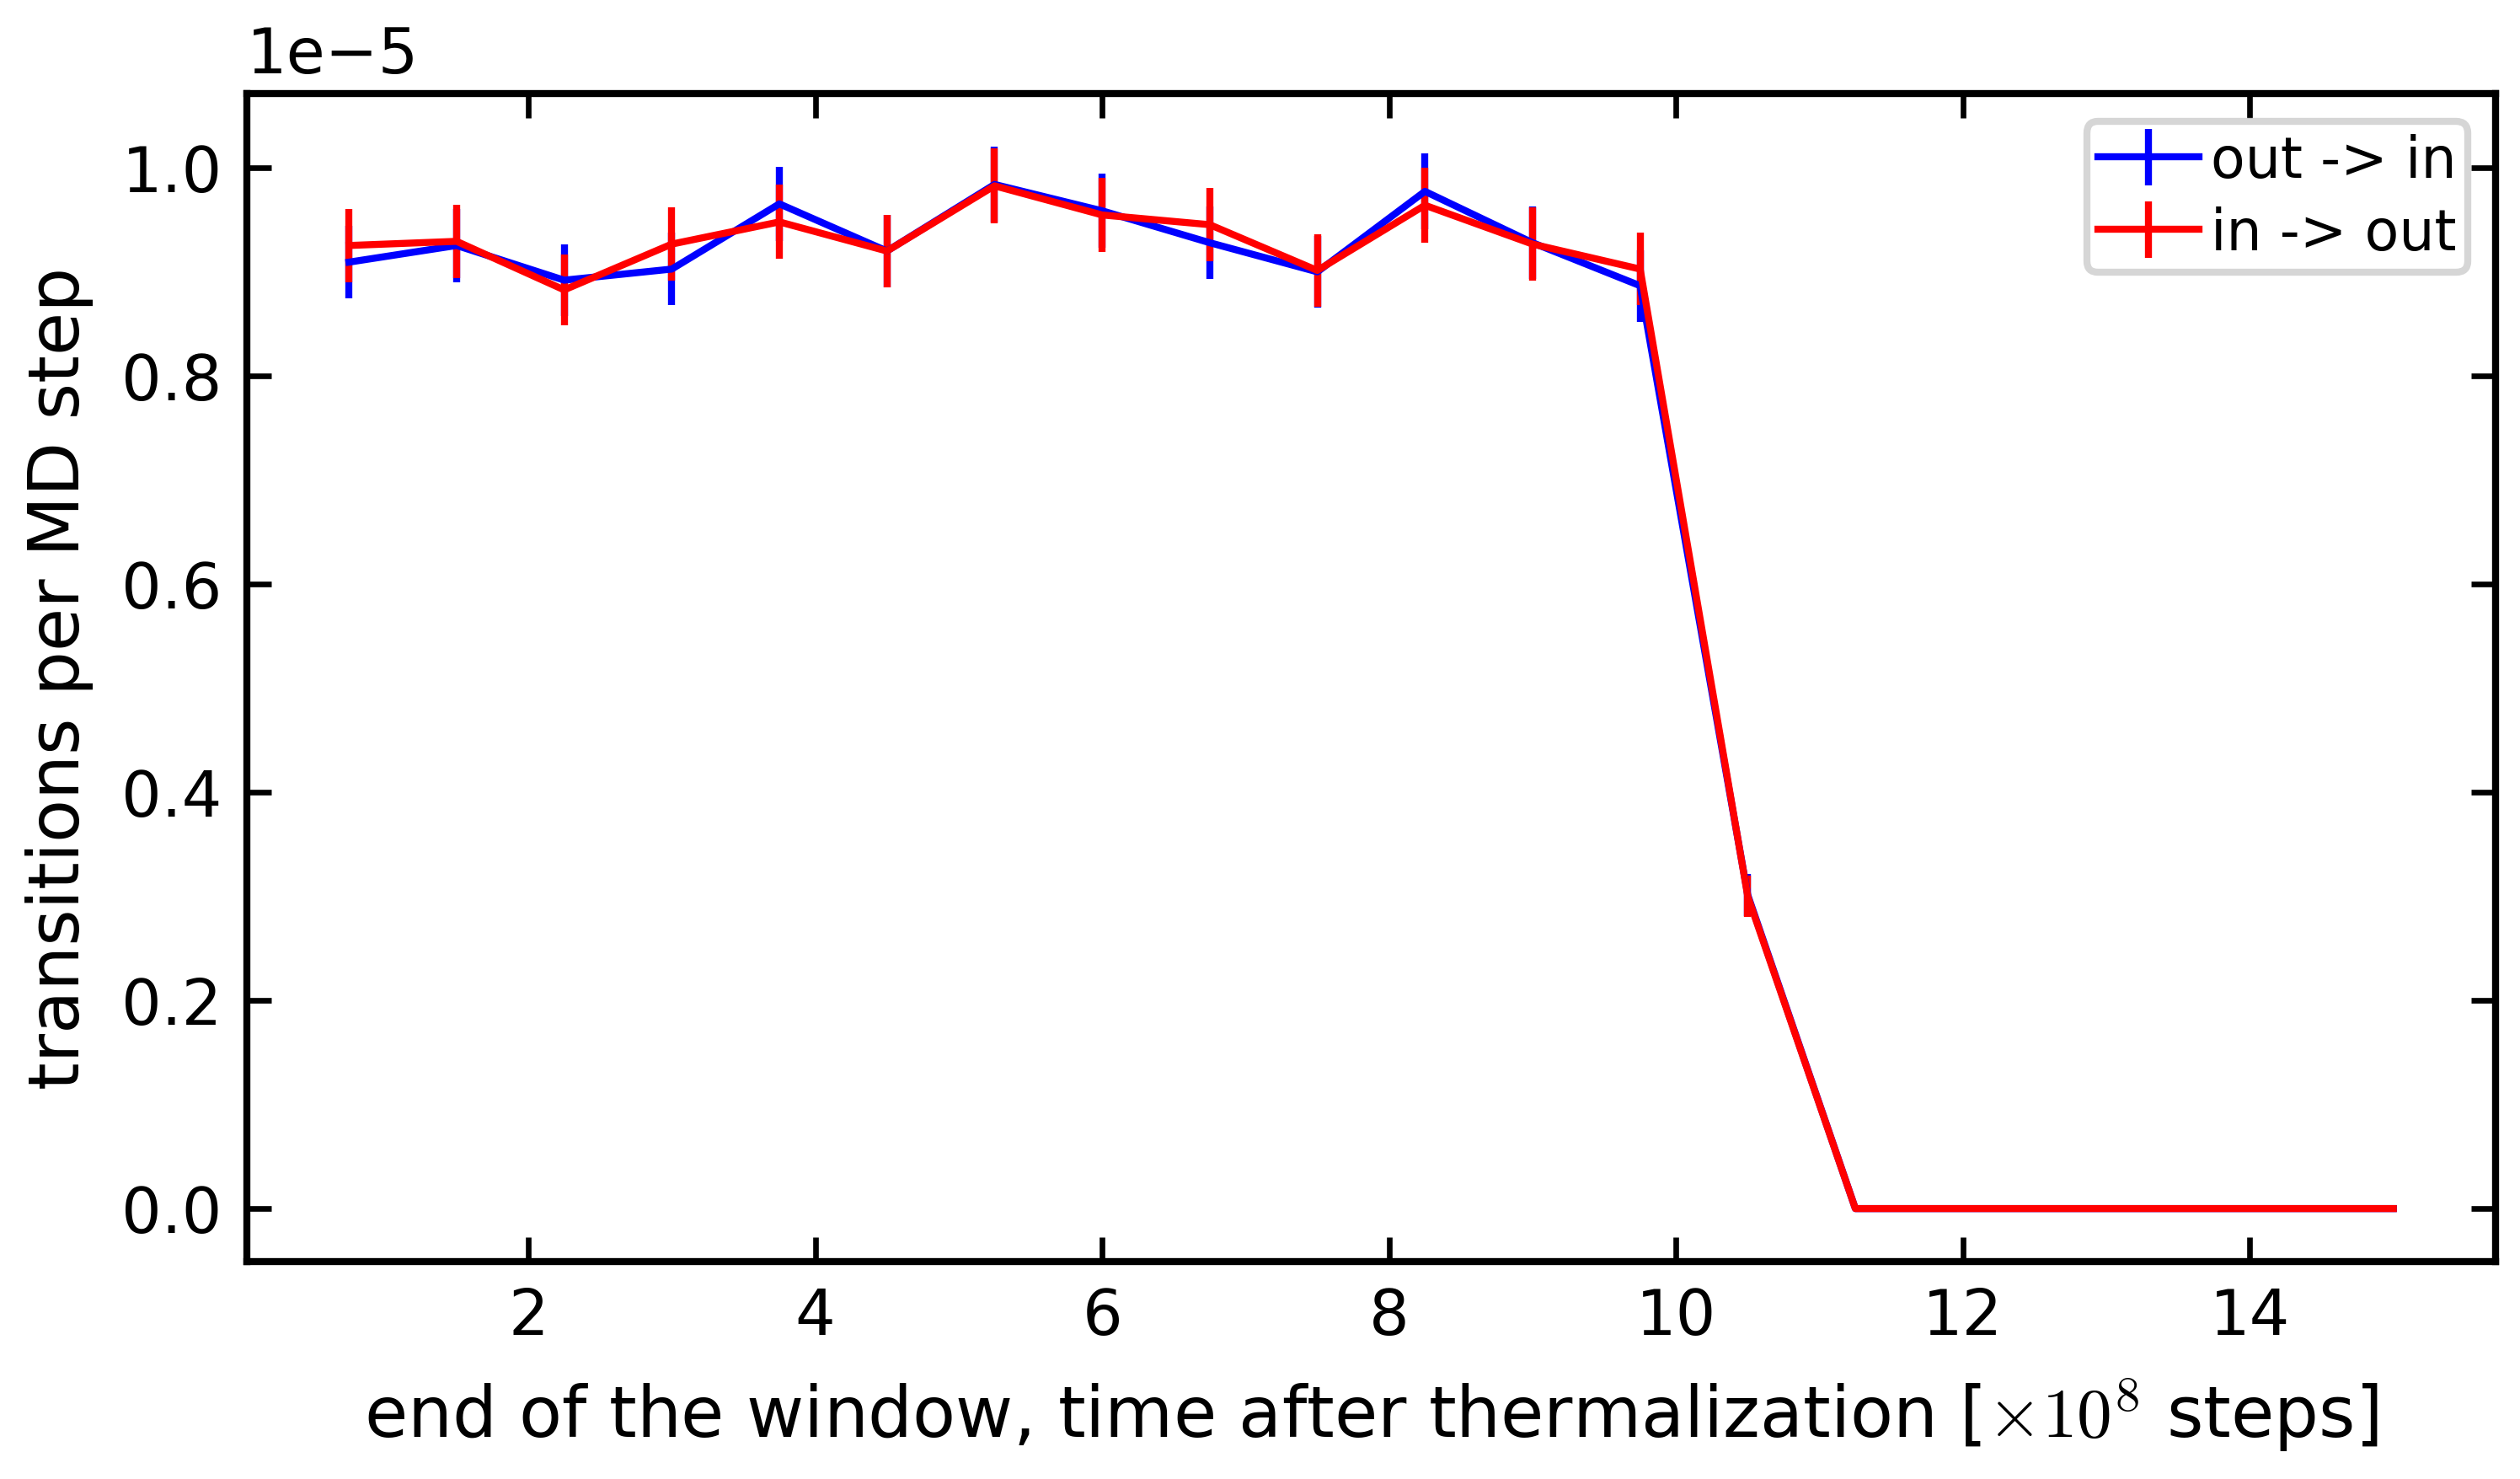

In [38]:
def k_in_out_vs_t(timelines, times):
    '''Number of out->in and in->out transitions per MD step (all chains, Poisson errors) in consecutive windows.'''
    kins, kouts, d_kins, d_kouts = [], [], [], []
    for t_in, t_fin in zip(times[:-1], times[1:]):
        counts = hpt.compute_rates(hpt.region_timelines(hpt.restrict_timelines(timelines, t_in, t_fin)))[2]
        n_in, n_out = counts.get(('out', 'in'), 0), counts.get(('in', 'out'), 0)
        kins.append(n_in / (t_fin - t_in))
        kouts.append(n_out / (t_fin - t_in))
        d_kins.append(np.sqrt(n_in) / (t_fin - t_in))
        d_kouts.append(np.sqrt(n_out) / (t_fin - t_in))
    return kins, kouts, d_kins, d_kouts


sim_type, n_k, n_p, ss = 'ness', 2, 24, 1
tl = hpt.load_timelines(timelines_file(sim_type, n_k, n_p, ss))
times = np.linspace(0., 1.5e9, 21)
kins, kouts, d_kins, d_kouts = k_in_out_vs_t(tl, times)

fig, ax = plt.subplots()
ax.errorbar(times[1:] / 1e8, kins, d_kins, c='b', label='out -> in')
ax.errorbar(times[1:] / 1e8, kouts, d_kouts, c='r', label='in -> out')
ax.set_xlabel(r'end of the window, time after thermalization [$\times 10^8$ steps]')
ax.set_ylabel('transitions per MD step')
ax.legend()
savefig(path_drop_fr_pl + f'{drop_name(sim_type, n_k, n_p)}/sim{ss}_in_out_transitions_vs_time_treshold{THRESHOLD}{TAG}')

# 6. Position of the reactions
Distance of every (de)phosphorylation from the centre of the largest condensate, per unit volume and time,
pooled over the replicas in `SIMS_REAC` (default: all of `SIMS`).
- density profiles: mean over replicas of the radial profiles from the centred dumps; band = SEM over replicas
- reaction densities: all events of all replicas / total simulated time; band = SEM of the per-replica densities

Figures get the tag `sims123` (replicas used) plus `TAG`, so the single-replica figures are not overwritten.

Profiles and distances are saved per replica (`sim{ss}_radial_profiles*.npz`, `sim{ss}_reaction_distances*.npz`) and reloaded.
For `RUN = ''` the reactions are taken from `_fr01_dump.gsd` (10-20 µs) and the density profiles from the centred
`_fr01_20us_dump` (20-30 µs): both at steady state, but not the same time window.

In [41]:
def reaction_distances_from_condensate(reaction_file, gsd_file, n_chains, chain_length, t_therm=0, cutoff=1.0):
    '''Distances of +1 and -1 reactions (columns 6-8: position) from the periodic COM of the largest
    substrate cluster in the snapshot closest in time to each reaction.'''
    data = np.atleast_2d(np.loadtxt(reaction_file, usecols=(0, 1, 2, 6, 7, 8), dtype=float))
    times = data[:, 0].astype(np.int64)
    changes = data[:, 2].astype(np.int8)
    reaction_positions = data[:, 3:6]

    keep = ((changes == 1) | (changes == -1)) & (times > t_therm)
    event_times = times[keep] - t_therm
    changes = changes[keep]
    reaction_positions = reaction_positions[keep]

    traj = gsd.hoomd.open(gsd_file, 'r')
    snapshot_times = np.array([traj[i].configuration.step for i in range(len(traj))])
    snapshot_indices = np.flatnonzero(snapshot_times >= t_therm)
    snapshot_times_rel = snapshot_times[snapshot_indices] - t_therm

    # nearest snapshot of each event
    idx = np.searchsorted(snapshot_times_rel, event_times)
    inside = (idx > 0) & (idx < len(snapshot_times_rel))
    event_times, changes, reaction_positions, idx = event_times[inside], changes[inside], reaction_positions[inside], idx[inside]
    use_right = np.abs(event_times - snapshot_times_rel[idx]) < np.abs(event_times - snapshot_times_rel[idx - 1])
    nearest_snapshots = snapshot_indices[np.where(use_right, idx, idx - 1)]

    gsd_box = traj[0].configuration.box
    box = freud.box.Box.from_box(gsd_box)
    cluster = freud.cluster.Cluster()
    substrate_n = n_chains * chain_length

    phospho_distances, dephospho_distances = [], []
    for si in tqdm(np.unique(nearest_snapshots)):
        mask = nearest_snapshots == si
        snap = traj[int(si)]
        positions = snap.particles.position[:substrate_n]
        masses = snap.particles.mass[:substrate_n]

        cluster.compute((box, positions), neighbors={'r_max': cutoff})
        condensate = np.flatnonzero(cluster.cluster_idx == np.argmax(np.bincount(cluster.cluster_idx)))
        com = hpa.trajectory.periodic_mass_weighted_com(positions[condensate], masses[condensate], gsd_box[:3])
        distances = hpa.trajectory.compute_distances_pbc(reaction_positions[mask], np.array([com]), *gsd_box[:3])[:, 0]

        phospho_distances.extend(distances[changes[mask] == 1])
        dephospho_distances.extend(distances[changes[mask] == -1])

    return np.asarray(phospho_distances), np.asarray(dephospho_distances)


def circle_square_intersection_area(R, a):
    '''Area of the intersection of a circle of radius R with the square [-a, a]^2.'''
    if R <= 0:
        return 0.0
    if R <= a:
        return np.pi * R**2
    if R >= np.sqrt(2) * a:
        return 4.0 * a**2
    return np.pi * R**2 - 4.0 * (R**2 * np.arccos(a / R) - a * np.sqrt(R**2 - a**2))


def sphere_cube_intersection_volume(r, L):
    '''Volume of a sphere of radius r (centred) inside a cubic box of side L.'''
    a = L / 2.0
    if r <= 0:
        return 0.0
    if r <= a:
        return 4.0 / 3.0 * np.pi * r**3
    if r >= np.sqrt(3) * a:
        return L**3
    return 2.0 * quad(lambda z: circle_square_intersection_area(np.sqrt(r**2 - z**2), a), 0.0, min(r, a),
                      epsabs=1e-8, epsrel=1e-8)[0]


def spherical_shell_volumes(bin_edges, L):
    return np.diff([sphere_cube_intersection_volume(r, L) for r in bin_edges])

In [42]:
sim_type, n_k, n_p = 'ness', 2, 24
SIMS_REAC = SIMS                                   # replicas pooled in this section
sims_tag = 'sims' + ''.join(str(ss) for ss in SIMS_REAC)
fig_dir = path_drop_fr_pl + f'{drop_name(sim_type, n_k, n_p)}/'

# particle groups: substrate (N_CHAINS x CHAIN_LENGTH beads), CK1d (292 beads each), PP3 (527 beads each)
start_ck1d = N_CHAINS * CHAIN_LENGTH
start_pp3 = start_ck1d + n_k * 292
groups = {'tdp': np.arange(0, start_ck1d),
          'ck1d': np.arange(start_ck1d, start_pp3),
          'pp3': np.arange(start_pp3, start_pp3 + n_p * 527)}

# radial densities of every replica (centred dumps) -> mean and SEM over replicas
rho_rep = {k: [] for k in groups}
for ss in SIMS_REAC:
    fn = an_dir(sim_type, n_k, n_p) + f'sim{ss}_radial_profiles{TAG}.npz'
    if RECOMPUTE or not os.path.exists(fn):
        dump_c_gsd = sim_prefix(sim_type, n_k, n_p, ss) + RUN_FILES['centered_dump']
        profiles = {}
        for k, group in groups.items():
            r_centers, profiles[k] = hpa.profiles.compute_radial_density_profile(dump_c_gsd, r_max=51, group=group, therm=0)
        np.savez(fn, r_centers=r_centers, **profiles)
    z = np.load(fn)
    r_centers = z['r_centers']
    for k in groups:
        rho_rep[k].append(z[k])
rho_rep = {k: np.array(v) for k, v in rho_rep.items()}
rho_mean = {k: v.mean(axis=0) for k, v in rho_rep.items()}
rho_sem = {k: v.std(axis=0, ddof=1) / np.sqrt(len(v)) if len(v) > 1 else np.zeros_like(v[0])
           for k, v in rho_rep.items()}
rho_tdp, rho_ck1d, rho_pp3 = rho_mean['tdp'], rho_mean['ck1d'], rho_mean['pp3']

# interface from the tanh fit of the replica-averaged substrate profile
popt, pcov = curve_fit(tanh_general, r_centers, rho_tdp)
dpopt = np.sqrt(pcov.diagonal())
R_cond, d_R_cond = popt[3], dpopt[3]
w, d_w = 1 / popt[2], dpopt[2] / popt[2]**2
print(f'{sims_tag}: R_cond = {R_cond:.3f} +- {d_R_cond:.3f} nm, w = {w:.2f} +- {d_w:.2f} nm')
for ss, rho in zip(SIMS_REAC, rho_rep['tdp']):   # replica-to-replica check
    p = curve_fit(tanh_general, r_centers, rho, p0=popt)[0]
    print(f'  sim{ss}: R_cond = {p[3]:.3f} nm, w = {1 / p[2]:.2f} nm')


def shade_interface(ax):
    ax.fill_between([0, R_cond - w], -1, 10, color='grey', alpha=0.2, lw=0)
    ax.fill_between([0, R_cond + w], -1, 10, color='grey', alpha=0.1, lw=0)

sims123: R_cond = 11.562 +- 0.009 nm, w = 2.93 +- 0.02 nm
  sim1: R_cond = 11.558 nm, w = 2.90 nm
  sim2: R_cond = 11.649 nm, w = 2.92 nm
  sim3: R_cond = 11.476 nm, w = 2.96 nm


In [ ]:
edges = np.append(r_centers - (r_centers[1] - r_centers[0]) / 2, r_centers[-1] + (r_centers[1] - r_centers[0]) / 2)   # bin edges


def stairs_band(ax, key, color, label, **kw):
    '''replica mean as stairs, SEM over replicas as a shaded band'''
    ax.stairs(rho_mean[key], edges, color=color, label=label, **kw)
    ax.stairs(rho_mean[key] + rho_sem[key], edges, baseline=rho_mean[key] - rho_sem[key],
              fill=True, color=color, alpha=0.2, lw=0)


f, ax = plt.subplots(figsize=(4.5, 2.7))
ax1 = ax.twinx()
stairs_band(ax, 'tdp', 'grey', 'TDP-43')
stairs_band(ax1, 'ck1d', 'b', r'CK1$\delta$')
stairs_band(ax1, 'pp3', 'violet', 'Calcineurin')
ax.plot(r_centers, tanh_general(r_centers, *popt), ls='--', c='k', label='profile fit', lw=0.8)
shade_interface(ax)
ax.axvline(R_cond, color='grey', ls='--', alpha=0.25)

ax.set_xlabel('r [nm]')
ax.set_ylabel(r'residue density [nm$^{-3}$]')
ax.legend(loc='upper center', frameon=False)
ax1.legend(loc='upper right', frameon=False)
ax.text(20, 2.45, r'R$_\mathrm{cond}$ = ' + f'{R_cond:.3f}({round(d_R_cond * 1000)}) nm', fontsize=8)
ax.text(20, 2.2, f'w = {w:.2f}({round(d_w * 100)}) nm', fontsize=8)
ax.text(10, 3.3, r'R$_\mathrm{cond}$', fontsize=8)
ax.set_ylim(0, 3.2)
ax.set_xlim(0, 50)
savefig(fig_dir + f'{sims_tag}_density_profile{TAG}')

In [44]:
L = 100.0
bins = np.linspace(0, np.sqrt(3) * L / 2, 51)
r = 0.5 * (bins[:-1] + bins[1:])
shell_volumes = spherical_shell_volumes(bins, L)

# reaction distances of every replica; time covered by its reaction dump after thermalization
phos_counts, dephos_counts, t_reac_us = [], [], []
for ss in SIMS_REAC:
    fn = an_dir(sim_type, n_k, n_p) + f'sim{ss}_reaction_distances{TAG}.npz'
    if RECOMPUTE or not os.path.exists(fn):
        prefix = sim_prefix(sim_type, n_k, n_p, ss)
        dump1_gsd = prefix + RUN_FILES['reaction_dump']
        phospho_r, dephospho_r = reaction_distances_from_condensate(prefix + RUN_FILES['reaction_contacts'], dump1_gsd,
                                                                    N_CHAINS, CHAIN_LENGTH, t_therm=T_THERM)
        with gsd.hoomd.open(dump1_gsd, 'r') as traj:
            t_us = steps_to_us(traj[-1].configuration.step - T_THERM)
        np.savez(fn, phospho=phospho_r, dephospho=dephospho_r, t_us=t_us)
    z = np.load(fn)
    phospho_r, dephospho_r = z['phospho'], z['dephospho']
    t_reac_us.append(float(z['t_us']))
    phos_counts.append(np.histogram(phospho_r, bins=bins)[0])
    dephos_counts.append(np.histogram(dephospho_r, bins=bins)[0])
    print(f'sim{ss}: {len(phospho_r)} phospho., {len(dephospho_r)} dephospho. in {t_reac_us[-1]:.1f} us')
phos_counts, dephos_counts, t_reac_us = np.array(phos_counts), np.array(dephos_counts), np.array(t_reac_us)

# pooled: events per volume per us = all events / total simulated time
phos_density = phos_counts.sum(axis=0) / shell_volumes / t_reac_us.sum()
dephos_density = dephos_counts.sum(axis=0) / shell_volumes / t_reac_us.sum()

# errors: SEM over replicas of the per-replica densities
phos_rep = phos_counts / shell_volumes / t_reac_us[:, None]
dephos_rep = dephos_counts / shell_volumes / t_reac_us[:, None]
n_rep = len(SIMS_REAC)
sem = (lambda x: x.std(axis=0, ddof=1) / np.sqrt(n_rep)) if n_rep > 1 else (lambda x: np.zeros(x.shape[1]))
d_phos_density, d_dephos_density = sem(phos_rep), sem(dephos_rep)
d_diff_density = sem(phos_rep - dephos_rep)

sim1: 2277 phospho., 2352 dephospho. in 10.0 us
sim2: 2155 phospho., 2259 dephospho. in 10.0 us
sim3: 2307 phospho., 2388 dephospho. in 10.0 us


In [45]:
phos_density.sum(), dephos_density.sum()

(0.16984831046480803, 0.05202952569830101)

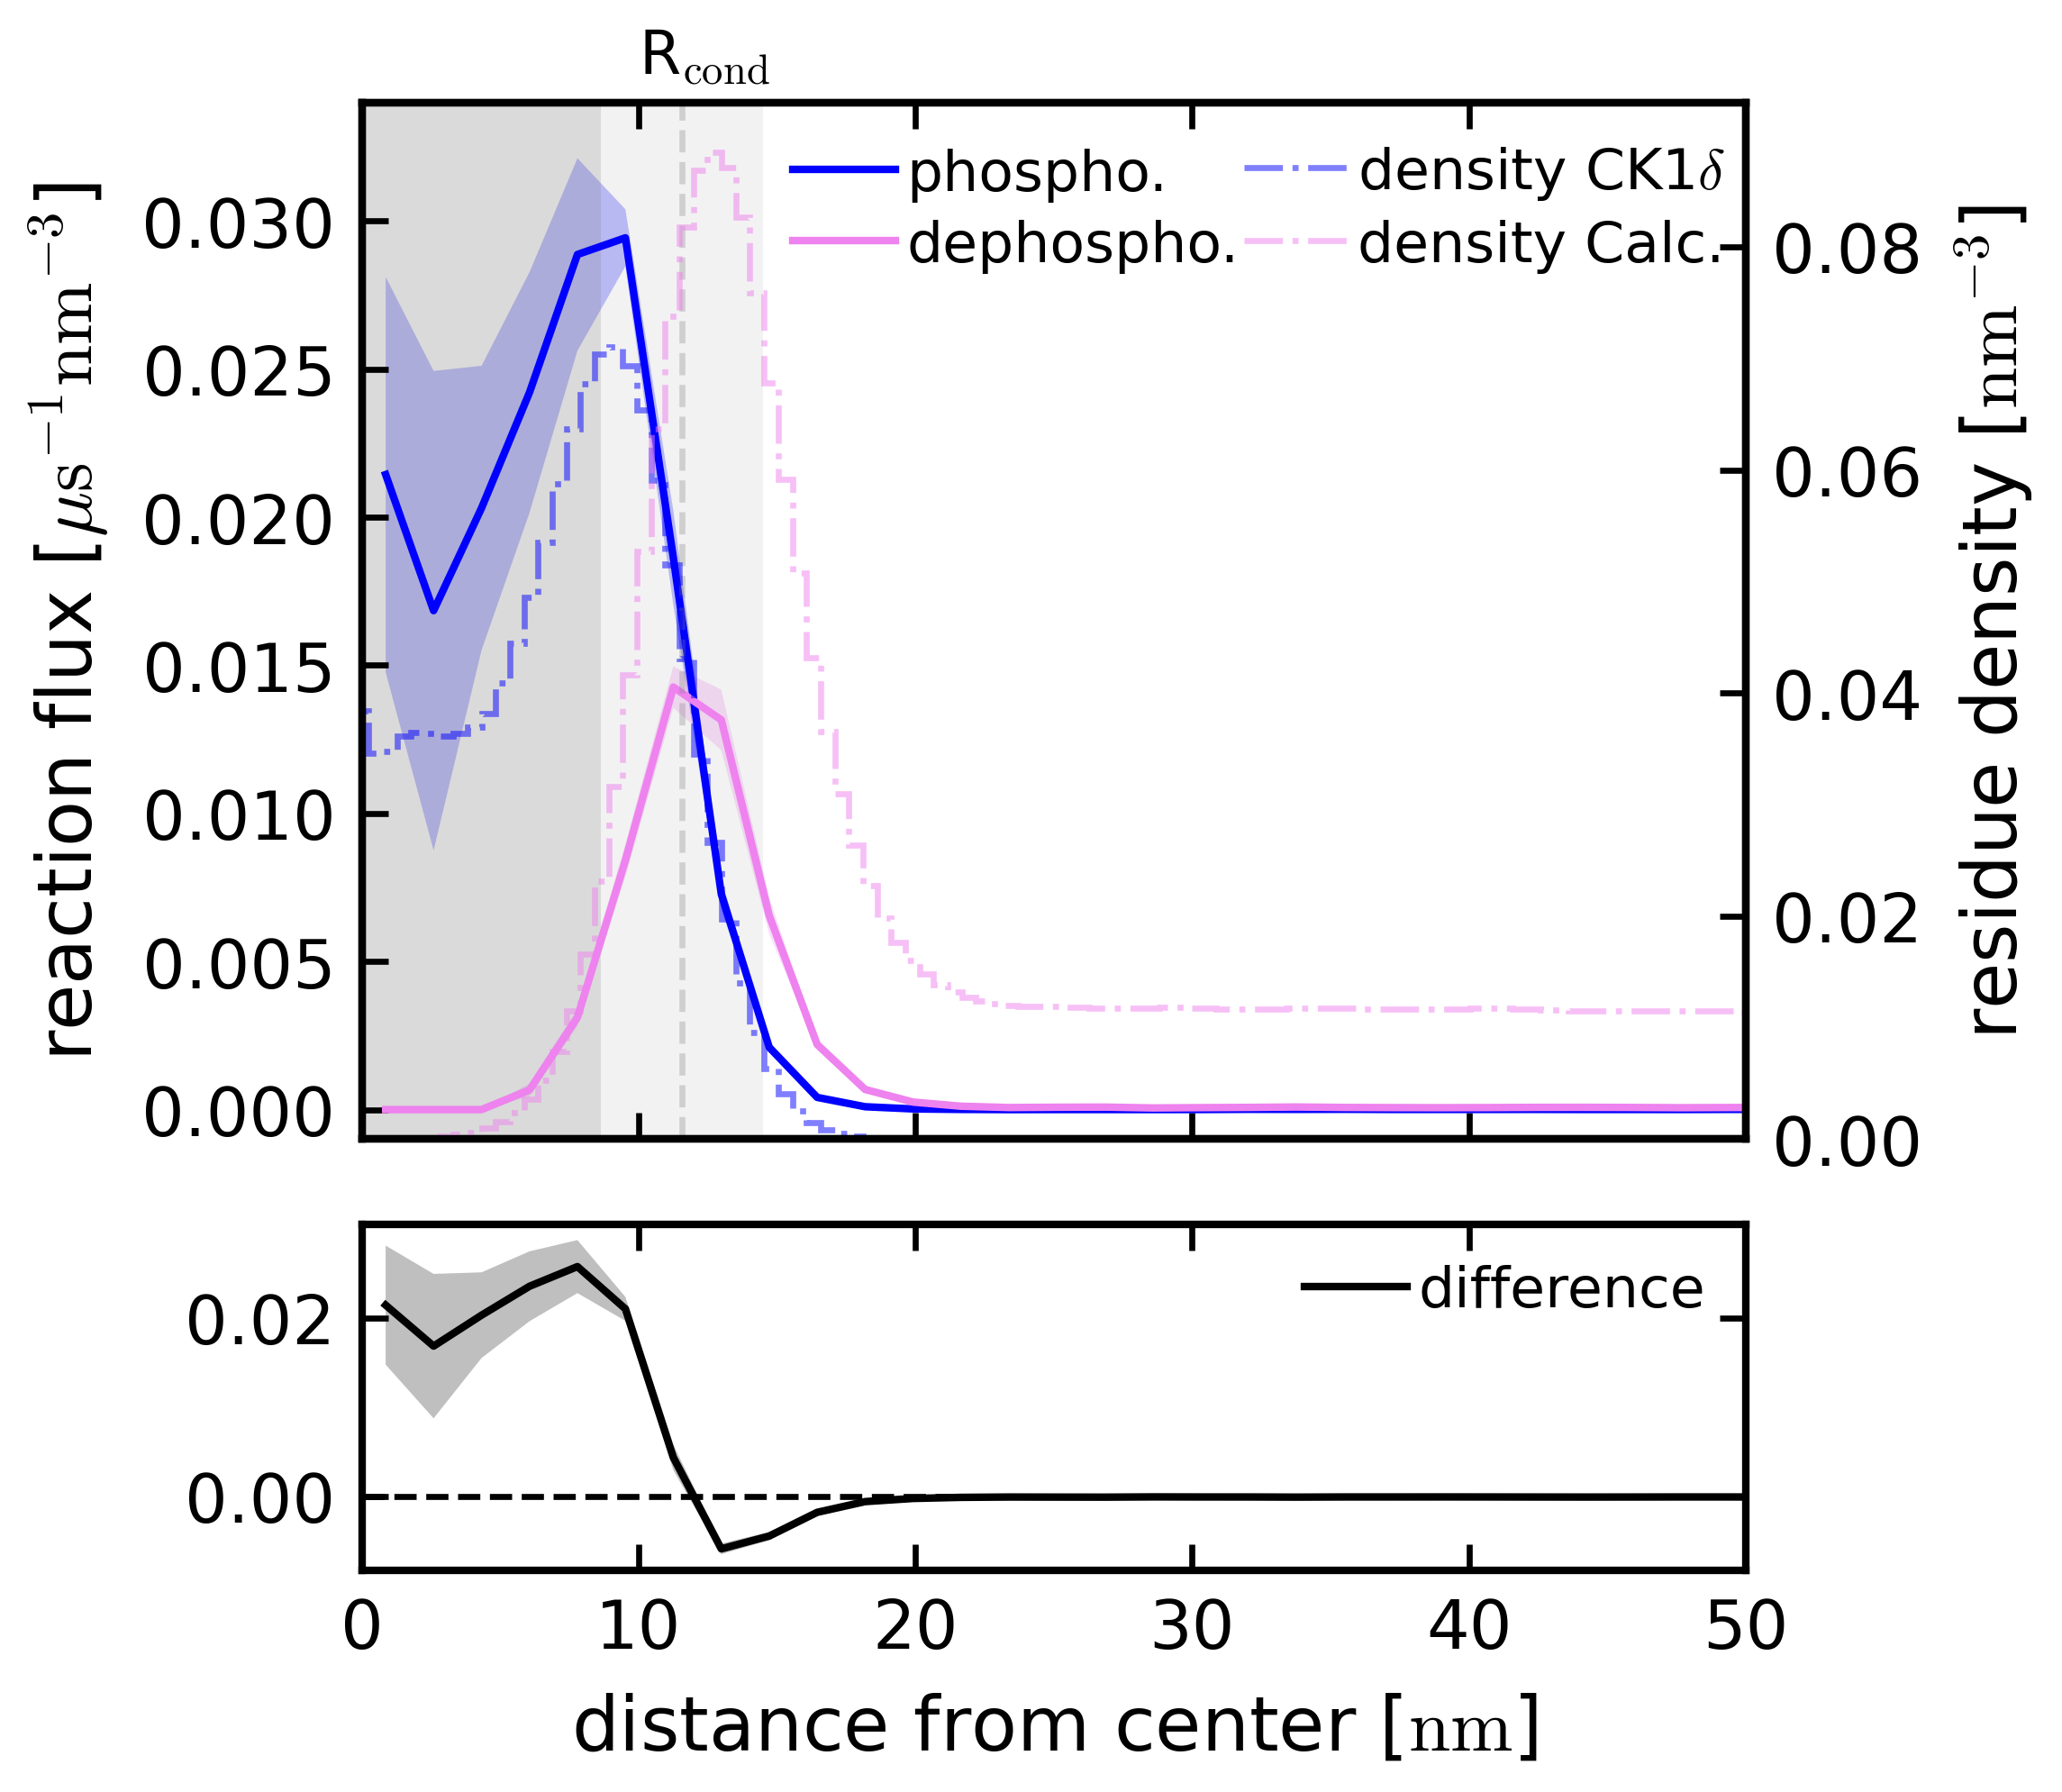

In [46]:
name = f'200-tdp-lcd_{n_k}-ck1d-open_{n_p}-pp3_fr01_{sims_tag}{TAG}'


def line_band(ax, x, y, dy, color, label=None, **kw):
    ax.plot(x, y, color=color, label=label, **kw)
    ax.fill_between(x, y - dy, y + dy, color=color, alpha=0.25, lw=0)


fig, (ax,axd) = plt.subplots(2,1,figsize=(3.8, 3.3), sharex=True, height_ratios=[3,1], layout='constrained')

ax1 = ax.twinx()
line_band(ax, r, phos_density, d_phos_density, 'b', 'phospho.')
line_band(ax, r, dephos_density, d_dephos_density, 'violet', 'dephospho.')
ax1.stairs(rho_ck1d, edges, label=r'density CK1$\delta$', color='b', lw=0.8, ls='-.', alpha=0.5)
ax1.stairs(rho_pp3, edges, label=r'density Calc.', color='violet', lw=0.8, ls='-.', alpha=0.5)
shade_interface(ax)
ax.axvline(R_cond, color='grey', ls='--', alpha=0.3, lw=0.8)
line_band(axd, r, phos_density - dephos_density, d_diff_density, 'k', 'difference')
axd.axhline(0, color='k', ls='--', lw=0.8)
axd.set_xlabel(r'distance from center [$\mathrm{nm}$]')
ax.set_ylabel(r'reaction flux [$\mathrm{\mu s^{-1} nm^{-3}}$]')
ax1.set_ylabel(r'residue density [$\mathrm{nm}^{-3}$]')
ax.text(10, 0.035, r'R$_\mathrm{cond}$', fontsize=8)
ax.legend(frameon=False, ncols=1, loc=(0.303,0.825), fontsize=7.6)
ax1.legend(frameon=False, ncols=1, loc=(0.629,0.825), fontsize=7.6)
axd.legend(frameon=False, ncols=2, fontsize=7.6)

ax.set_xlim(0, 50)
ax.set_ylim(-0.001, 0.034)

savefig(fig_dir + f'reactions_position_{name}', dpi=600)


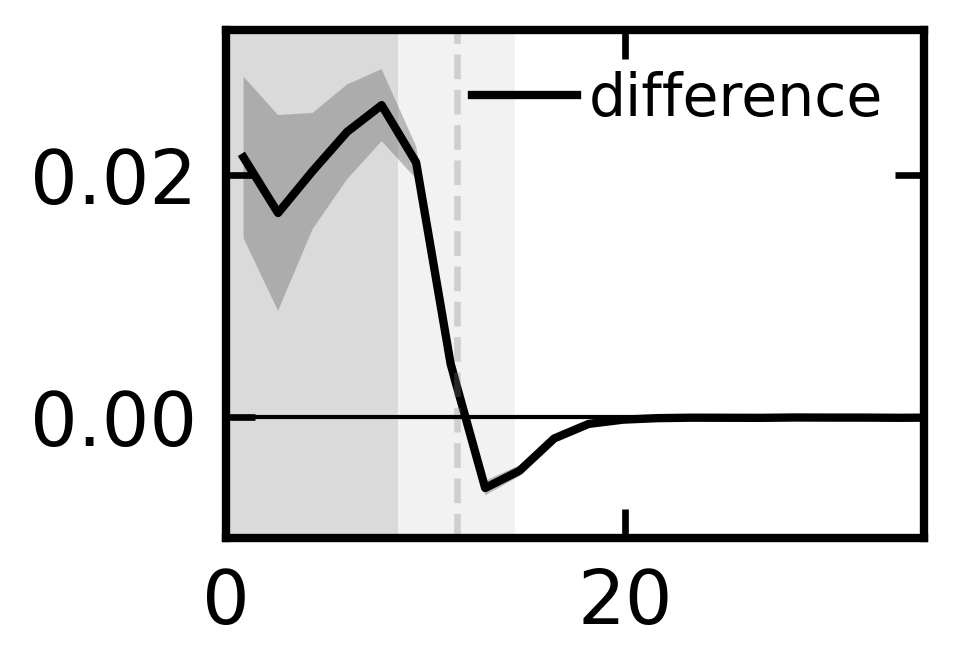

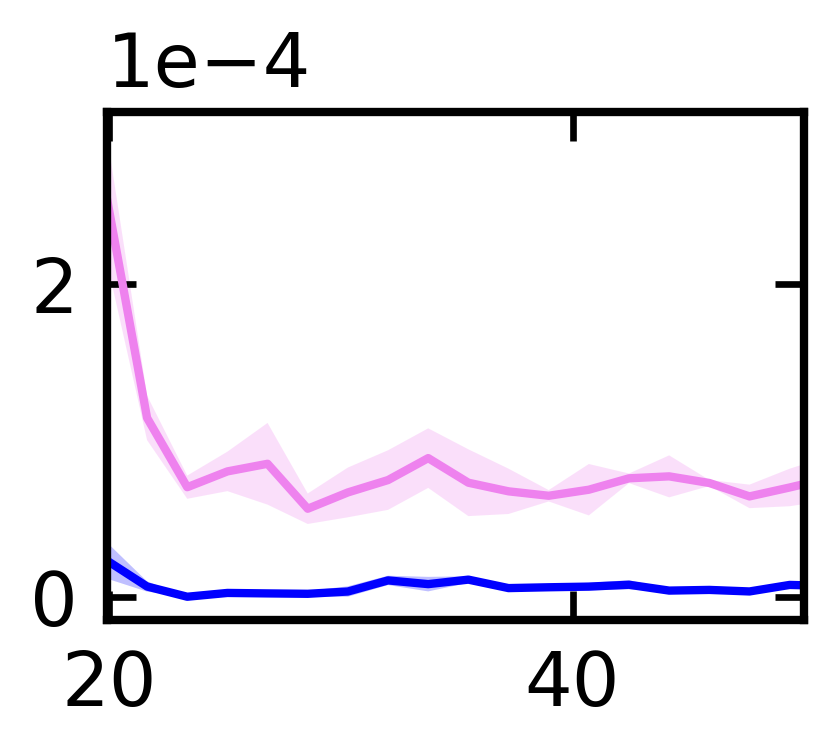

In [47]:
fig, ax = plt.subplots(figsize=(1.5, 1.1))
line_band(ax, r, phos_density - dephos_density, d_diff_density, 'k', 'difference')
shade_interface(ax)
ax.axvline(R_cond, color='grey', ls='--', alpha=0.3, lw=0.8)
ax.axhline(0, color='k', ls='-', lw=0.5)
#ax.set_xlabel('distance from condensate center')
#ax.set_ylabel(r'events per $\mu$s/volume')
ax.legend(frameon=False, ncols=2, fontsize=7)
ax.set_xlim(0, 35)
ax.set_ylim(-0.01, 0.032)
savefig(fig_dir + f'diff_reactions_position_{name}', dpi=600)

fig, ax = plt.subplots(figsize=(1.5, 1.1))
cut_r = 11
line_band(ax, r[cut_r:], phos_density[cut_r:], d_phos_density[cut_r:], 'b', 'Phosphorylation')
line_band(ax, r[cut_r:], dephos_density[cut_r:], d_dephos_density[cut_r:], 'violet', 'Dephosphorylation')
ax.set_xlim(r[cut_r], 50)
savefig(fig_dir + f'inset_reactions_position_{name}', dpi=600)